# Lab 7 - Modele generatywne: VAE i GAN + sprawozdanie końcowe

> **Wersja z rozwiązaniami.** Wszystkie komórki `# TODO` zostały uzupełnione.

## Cel zajęć

Na Lab 6 autoenkoder uczył się **kompresować i odtwarzać** dane. Dziś idziemy krok dalej: chcemy **generować nowe** obrazy, których nie było w zbiorze uczącym. Poznamy dwie najważniejsze rodziny klasycznych głębokich modeli generatywnych:
- **VAE** (Variational Autoencoder) - autoenkoder z probabilistyczną, regularną przestrzenią latentną, z której można losować,
- **GAN** (Generative Adversarial Network) - gra dwóch sieci: generatora i dyskryminatora.

Ostatnia część zajęć to **instrukcja i checklista sprawozdania końcowego**, które przesyłasz po tym laboratorium.

Po zajęciach student potrafi:
- wyjaśnić trik reparametryzacji i dwa składniki straty VAE (rekonstrukcja + KL) oraz zaimplementować VAE w Keras 3 z własnym `train_step`,
- wizualizować i interpretować przestrzeń latentną VAE, generować siatkę obrazów i interpolować między przykładami,
- zbudować DCGAN w Keras 3 (dwie sieci, dwa optymalizatory, dwie taśmy gradientów), monitorować straty G i D oraz próbki po epokach,
- rozpoznać objawy niestabilności i *mode collapse* i zmierzyć różnorodność próbek prostym klasyfikatorem,
- *(opcjonalnie)* napisać tę samą pętlę GAN w PyTorch,
- przygotować sprawozdanie końcowe zgodne z wymaganiami.

**Efekty uczenia (karta przedmiotu):** UGŁ_W01, UGŁ_W02 (modele generatywne, zaawansowane narzędzia: własne pętle uczenia), UGŁ_U01 (hipotezy - np. wpływ wagi KL $\beta$), UGŁ_U02 (usprawnienia - stabilizacja GAN), UGŁ_K01 (świadomość rozwoju dziedziny: dyfuzja, etyka deepfake).

**Powiązanie z wykładem:** W5 (VAE, GAN, minimax, mode collapse, DCGAN, FID, dyfuzja, etyka), W3 (optymalizatory, pętla treningowa w PyTorch), W2 (splot transponowany), Lab 6 (autoenkodery).

### Harmonogram (180 min)

| Czas | Blok |
|---|---|
| 0-10 min | 0. Przygotowanie środowiska, dane |
| 10-60 min | 1-2. VAE: próbkowanie, strata, trening, przestrzeń latentna, interpolacja, $\beta$ (Zadania 2.1-2.4) |
| 60-70 min | **Przerwa** |
| 70-130 min | 3. DCGAN w Keras: generator, `train_step`, monitorowanie, interpolacja, mode collapse (Zadania 3.1-3.4) |
| 130-145 min | 4. *(opcjonalnie)* GAN w PyTorch - wersja skrócona (Zadanie 4.1) |
| 145-155 min | 5. Dyfuzja i etyka - krótka dyskusja |
| 155-175 min | 6. Sprawozdanie końcowe: instrukcja, checklista, pytania |
| 175-180 min | Pytania kontrolne i podsumowanie kursu |

### Wymagania wstępne
- Lab 6: autoenkoder gęsty i konwolucyjny w Keras, `Conv2DTranspose`.
- Lab 1: `tf.GradientTape`; Lab 2/5: pętla treningowa w PyTorch.
- Rozkład normalny, wartość oczekiwana, logarytm; intuicja dywergencji KL z W5.

## 0. Przygotowanie środowiska

1. W Colab: **Środowisko wykonawcze -> Zmień typ środowiska -> T4 GPU**. GAN-y bez GPU trenują się bardzo wolno.
2. Uruchom komórki po kolei.

Zmienna `SZYBKI_TRYB`: przy `False` trenujemy na pełnych zbiorach (60 000 obrazów) z liczbą epok dającą ładne próbki. **Jeśli pracujesz bez GPU, ustaw `SZYBKI_TRYB = True`** - użyjemy 2000 obrazów i 1-2 epok; wygenerowane obrazy będą wtedy rozmytymi plamami, ale sprawdzisz, że cały kod działa.

**Ważne - Keras 3:** w Colab Keras 3 działa domyślnie na backendzie TensorFlow. Nasze własne `train_step` używają `tf.GradientTape`, więc wymagają backendu `tensorflow` (ustawiamy go jawnie przed importem). Operacje na tensorach piszemy przez `keras.ops` (np. `ops.exp`, `ops.mean`), a losowość przez `keras.random` z `SeedGenerator`.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"   # wymagane: train_step z tf.GradientTape
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
from scipy.stats import norm

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| backend:", keras.backend.backend())
assert keras.backend.backend() == "tensorflow", "Zrestartuj sesję - potrzebny backend tensorflow"

TensorFlow: 2.21.0 | Keras: 3.13.2 | backend: tensorflow


In [2]:
gpus = tf.config.list_physical_devices("GPU")
print("Dostępne GPU:", gpus if gpus else "brak - pracujesz na CPU (rozważ SZYBKI_TRYB = True)")

SEED = 42
keras.utils.set_random_seed(SEED)   # seedy Python / NumPy / TF

# Tryb szybki: True, jeśli pracujesz bez GPU (mniej epok i danych)
SZYBKI_TRYB = os.environ.get("DL_FAST", "0") == "1"
# SZYBKI_TRYB = True   # <- odkomentuj, jeśli nie masz GPU

N_TRAIN = 2000 if SZYBKI_TRYB else 60000
EPOKI_VAE = 2 if SZYBKI_TRYB else 30
EPOKI_KROTKO = 1 if SZYBKI_TRYB else 10
EPOKI_GAN = 2 if SZYBKI_TRYB else 30
EPOKI_TORCH = 1 if SZYBKI_TRYB else 10
LATENT_GAN = 64 if SZYBKI_TRYB else 128
print(f"SZYBKI_TRYB={SZYBKI_TRYB}, N_TRAIN={N_TRAIN}, EPOKI_VAE={EPOKI_VAE}, EPOKI_GAN={EPOKI_GAN}")

Dostępne GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
SZYBKI_TRYB=False, N_TRAIN=60000, EPOKI_VAE=30, EPOKI_GAN=30


In [3]:
# Dane: MNIST dla VAE (piksele w [0, 1]) i Fashion-MNIST dla GAN (piksele w [-1, 1])
(xm_tr, ym_tr), (xm_te, ym_te) = keras.datasets.mnist.load_data()
x_mnist = (xm_tr[:N_TRAIN].astype("float32") / 255.0)[..., None]       # (N, 28, 28, 1)
y_mnist = ym_tr[:N_TRAIN]
x_mnist_te = (xm_te[:2000 if SZYBKI_TRYB else 10000].astype("float32") / 255.0)[..., None]
y_mnist_te = ym_te[:len(x_mnist_te)]

(xf_tr, yf_tr), (xf_te, yf_te) = keras.datasets.fashion_mnist.load_data()
x_fash = (xf_tr[:N_TRAIN].astype("float32") / 127.5 - 1.0)[..., None]  # skalowanie do [-1, 1] pod tanh
y_fash = yf_tr[:N_TRAIN]
x_fash_te = (xf_te[:2000 if SZYBKI_TRYB else 10000].astype("float32") / 127.5 - 1.0)[..., None]
y_fash_te = yf_te[:len(x_fash_te)]
KLASY_FASHION = ["T-shirt", "spodnie", "sweter", "sukienka", "płaszcz",
                 "sandał", "koszula", "sneaker", "torba", "botek"]
print("MNIST:", x_mnist.shape, x_mnist.min(), x_mnist.max(), "| Fashion:", x_fash.shape, x_fash.min(), x_fash.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MNIST: (60000, 28, 28, 1) 0.0 1.0 | Fashion: (60000, 28, 28, 1) -1.0 1.0


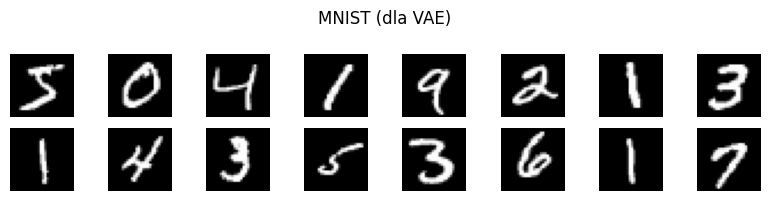

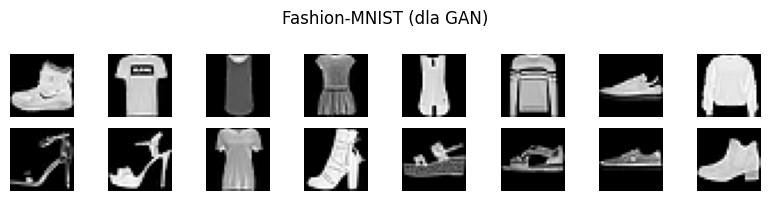

In [4]:
def plansza(obrazy, n_wierszy, n_kolumn, tytul="", zakres=(0, 1), rozmiar=1.0):
    # Rysuje obrazy (N, 28, 28[, 1]) jako jedną planszę n_wierszy x n_kolumn
    obrazy = np.asarray(obrazy).reshape(-1, 28, 28)[: n_wierszy * n_kolumn]
    fig, axes = plt.subplots(n_wierszy, n_kolumn, figsize=(rozmiar * n_kolumn, rozmiar * n_wierszy))
    for ax, im in zip(np.atleast_1d(axes).flat, obrazy):
        ax.imshow(im, cmap="gray", vmin=zakres[0], vmax=zakres[1]); ax.axis("off")
    fig.suptitle(tytul); plt.tight_layout(); plt.show()

plansza(x_mnist[:16], 2, 8, "MNIST (dla VAE)")
plansza(x_fash[:16], 2, 8, "Fashion-MNIST (dla GAN)", zakres=(-1, 1))

## 1. Od autoenkodera do modelu generatywnego

Model generatywny uczy się (jawnie lub niejawnie) **rozkładu danych** $p(\mathbf{x})$, tak aby móc losować z niego nowe próbki. Na Lab 6 widzieliśmy, że dekoder zwykłego AE potrafi zamienić punkt $\mathbf{z}$ na obraz, ale **nie wiemy, skąd losować $\mathbf{z}$**: przestrzeń latentna AE ma dziury, nierówną gęstość i nieznany kształt. Wylosowanie punktu "pomiędzy" skupieniami daje często nieczytelny kształt.

**Pomysł VAE:** wymusić, żeby rozkład kodów był bliski prostemu rozkładowi a priori $p(\mathbf{z}) = \mathcal{N}(\mathbf{0}, I)$. Wtedy generowanie jest trywialne: losujemy $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, I)$ i podajemy do dekodera.

**Pomysł GAN:** nie modelujemy gęstości wprost. Generator $G(\mathbf{z})$ zamienia szum na obraz, a dyskryminator $D(\mathbf{x})$ ocenia, czy obraz jest prawdziwy. Generator uczy się "oszukiwać" dyskryminator.

| | AE (Lab 6) | VAE | GAN |
|---|---|---|---|
| Cel | rekonstrukcja | rekonstrukcja + regularny latent | realistyczne próbki |
| Enkoder | tak | tak (probabilistyczny) | brak |
| Losowanie nowych próbek | niepewne | tak, z $\mathcal{N}(0, I)$ | tak, z $\mathcal{N}(0, I)$ |
| Typowa jakość obrazów | - | lekko rozmyte | ostre |
| Stabilność treningu | wysoka | wysoka | niska (gra dwóch graczy) |

## 2. VAE - wariacyjny autoenkoder

### Teoria (W5)

Enkoder VAE nie zwraca jednego punktu, lecz **parametry rozkładu** $q_\phi(\mathbf{z}|\mathbf{x}) = \mathcal{N}(\boldsymbol{\mu}(\mathbf{x}), \operatorname{diag}\boldsymbol{\sigma}^2(\mathbf{x}))$. Dla stabilności numerycznej sieć zwraca $\log\boldsymbol{\sigma}^2$ (`z_log_var`) zamiast $\boldsymbol{\sigma}$ - może on przyjmować dowolne wartości rzeczywiste.

Uczymy maksymalizując dolne ograniczenie wiarygodności (ELBO), czyli minimalizując
$$\mathcal{L}(\mathbf{x}) = \underbrace{-\mathbb{E}_{q_\phi(\mathbf{z}|\mathbf{x})}\left[\log p_\theta(\mathbf{x}|\mathbf{z})\right]}_{\text{rekonstrukcja (BCE po pikselach)}} + \beta \cdot \underbrace{D_{KL}\left(q_\phi(\mathbf{z}|\mathbf{x}) \,\|\, \mathcal{N}(\mathbf{0}, I)\right)}_{\text{regularyzacja latentu}}$$
gdzie standardowy VAE ma $\beta = 1$. Dla rozkładów normalnych KL ma postać zamkniętą:
$$D_{KL} = -\frac{1}{2}\sum_{j=1}^{d}\left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right).$$

**Trik reparametryzacji:** losowanie $\mathbf{z} \sim \mathcal{N}(\boldsymbol\mu, \boldsymbol\sigma^2)$ nie jest różniczkowalne względem $\boldsymbol\mu, \boldsymbol\sigma$. Przepisujemy je jako
$$\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma} \odot \boldsymbol{\epsilon}, \quad \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, I), \quad \boldsymbol\sigma = \exp\left(\tfrac{1}{2}\log\boldsymbol\sigma^2\right).$$
Losowość jest teraz w $\boldsymbol\epsilon$ (stała z punktu widzenia gradientu), a gradient płynie przez $\boldsymbol\mu$ i $\boldsymbol\sigma$.

**Intuicja dwóch składników:** sama rekonstrukcja dałaby zwykły AE (σ -> 0, kody rozrzucone byle jak). Sam KL ściągnąłby wszystkie kody do $\mathcal{N}(0, I)$ i dekoder nie miałby żadnej informacji. Kompromis daje przestrzeń jednocześnie **informatywną i regularną**.

### Zadanie 2.1 - warstwa próbkowania (trik reparametryzacji)

Uzupełnij metodę `call` warstwy `Sampling`: na wejściu para `(z_mean, z_log_var)`, na wyjściu $\mathbf{z} = \boldsymbol\mu + \exp(0.5 \log\boldsymbol\sigma^2)\odot\boldsymbol\epsilon$.

**Wymagania Keras 3:** używaj `keras.ops` (`ops.exp`, `ops.shape`) oraz `keras.random.normal(shape, seed=self.seed_generator)`. Nie używaj `tf.random.normal` ani `K.random_normal` z Keras 2 - działają inaczej lub nie istnieją.

**Kryteria sukcesu:** test w komórce poniżej - dla `z_mean = 3`, `z_log_var = log(0.25)` średnia próbek ok. 3.0, odchylenie standardowe ok. 0.5.

In [5]:
class Sampling(layers.Layer):
    # Warstwa realizująca trik reparametryzacji: z = mu + sigma * eps
    def __init__(self, seed=SEED, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator(seed)   # stan generatora losowego w Keras 3

    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = keras.random.normal(ops.shape(z_mean), seed=self.seed_generator)   # eps ~ N(0, I)
        return z_mean + ops.exp(0.5 * z_log_var) * eps                            # z = mu + sigma * eps

# Test warstwy
mu_t = np.full((20000, 2), 3.0, dtype="float32")
lv_t = np.full((20000, 2), np.log(0.25), dtype="float32")
z_t = ops.convert_to_numpy(Sampling()([mu_t, lv_t]))
print("średnia:", z_t.mean(0).round(3), "| odch. std.:", z_t.std(0).round(3), "(oczekiwane ok. 3.0 i 0.5)")

średnia: [3.008 2.997] | odch. std.: [0.502 0.499] (oczekiwane ok. 3.0 i 0.5)


### Enkoder i dekoder VAE

Architektura konwolucyjna, jak CAE z Lab 6, ale enkoder ma **trzy wyjścia**: `z_mean`, `z_log_var` i wylosowane `z`. Latent ma tylko **2 wymiary**, żeby dało się go narysować. Dekoder kończy się `sigmoid` (piksele w $[0,1]$, strata BCE).

In [6]:
LATENT_VAE = 2

def zbuduj_enkoder_vae(latent_dim=LATENT_VAE):
    wej = keras.Input(shape=(28, 28, 1))
    h = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(wej)   # 14x14x32
    h = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(h)     # 7x7x64
    h = layers.Flatten()(h)
    h = layers.Dense(16, activation="relu")(h)
    z_mean = layers.Dense(latent_dim, name="z_mean")(h)         # średnia rozkładu q(z|x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(h)   # log wariancji (dowolna liczba rzeczywista)
    z = Sampling(name="z")([z_mean, z_log_var])                 # próbka z rozkładu (trik reparametryzacji)
    return keras.Model(wej, [z_mean, z_log_var, z], name="vae_enkoder")

def zbuduj_dekoder_vae(latent_dim=LATENT_VAE):
    wej = keras.Input(shape=(latent_dim,))
    h = layers.Dense(7 * 7 * 64, activation="relu")(wej)
    h = layers.Reshape((7, 7, 64))(h)
    h = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(h)   # 14x14
    h = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(h)   # 28x28
    wyj = layers.Conv2D(1, 3, padding="same", activation="sigmoid")(h)
    return keras.Model(wej, wyj, name="vae_dekoder")

enc_vae = zbuduj_enkoder_vae()
dec_vae = zbuduj_dekoder_vae()
enc_vae.summary()

Model: "vae_enkoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 14, 14,    │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │     50,192 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │         34 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │         34 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 69,076 (269.83 KB)

 Trainable params: 69,076 (269.83 KB)

 Non-trainable params: 0 (0.00 B)

### Model VAE z własnym `train_step` (Keras 3)

Strata VAE zależy od wewnętrznych tensorów (`z_mean`, `z_log_var`), więc nie pasuje do schematu `compile(loss=...)`. Nadpisujemy `train_step` w podklasie `keras.Model`. Wzorzec Keras 3 (backend TF):

1. `with tf.GradientTape() as tape:` - przebieg w przód i policzenie straty,
2. `tape.gradient(strata, self.trainable_weights)`,
3. `self.optimizer.apply_gradients(zip(grads, self.trainable_weights))`,
4. aktualizacja metryk-śledzących (`keras.metrics.Mean`) i zwrócenie słownika `{nazwa: wartość}`.

**Pułapki Keras 3 vs Keras 2 (często w starych tutorialach):**
- nie ma `self.compiled_loss` / `self.compiled_metrics` w starym stylu - używamy własnych `keras.metrics.Mean`,
- metryki muszą być zwrócone przez właściwość `metrics`, żeby Keras resetował je na początku każdej epoki,
- `fit(x)` bez `y` przekazuje do `train_step` same dane albo krotkę - obsługujemy oba przypadki,
- operacje matematyczne przez `keras.ops`, nie `K.` (moduł `keras.backend` z Keras 2 jest okrojony).

**Skala straty:** rekonstrukcję **sumujemy po pikselach** (784 składniki), a KL po wymiarach latentu, i dopiero potem uśredniamy po batchu. Jeśli uśrednisz BCE po pikselach, rekonstrukcja będzie ok. 784 razy "słabsza" od KL i VAE wygeneruje same rozmyte średnie (*posterior collapse*).

### Zadanie 2.2 - strata VAE w `train_step`

W metodzie `oblicz_straty` uzupełnij:
- `rec_loss` - BCE między `data` a `rekonstrukcja`, zsumowana po osiach (1, 2) (kanał już redukuje `keras.losses.binary_crossentropy`), uśredniona po batchu,
- `kl_loss` - wzór na $D_{KL}$ z teorii, zsumowany po wymiarach latentu (oś 1), uśredniony po batchu.

Metodę `oblicz_straty` wykorzystują zarówno `train_step`, jak i `test_step` (walidacja).

**Kryteria sukcesu:** trening startuje, `kl_loss` jest dodatnia, `loss` = `rec_loss` + β·`kl_loss` maleje. W pełnym trybie po 30 epokach `loss` ok. 150-160, `kl_loss` ok. 5-7.

In [7]:
class VAE(keras.Model):
    def __init__(self, enkoder, dekoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.enkoder, self.dekoder, self.beta = enkoder, dekoder, beta
        # Metryki-śledzące: średnia bieżąca w epoce
        self.loss_tracker = keras.metrics.Mean(name="loss")
        self.rec_tracker = keras.metrics.Mean(name="rec_loss")
        self.kl_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        # Lista metryk resetowanych automatycznie na początku każdej epoki
        return [self.loss_tracker, self.rec_tracker, self.kl_tracker]

    def call(self, x, training=False):
        # Przebieg w przód (dla predict): rekonstrukcja z wylosowanego z
        _, _, z = self.enkoder(x, training=training)
        return self.dekoder(z, training=training)

    def oblicz_straty(self, data, training):
        z_mean, z_log_var, z = self.enkoder(data, training=training)
        rekonstrukcja = self.dekoder(z, training=training)
        # BCE: binary_crossentropy redukuje oś kanału -> (batch, 28, 28); SUMA po pikselach, średnia po batchu
        rec_loss = ops.mean(ops.sum(keras.losses.binary_crossentropy(data, rekonstrukcja), axis=(1, 2)))
        # KL(N(mu, sigma^2) || N(0, I)) = -1/2 * sum(1 + log sigma^2 - mu^2 - sigma^2)
        kl = -0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var))
        kl_loss = ops.mean(ops.sum(kl, axis=1))
        return rec_loss + self.beta * kl_loss, rec_loss, kl_loss

    def _aktualizuj(self, total, rec, kl):
        self.loss_tracker.update_state(total)
        self.rec_tracker.update_state(rec)
        self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def train_step(self, data):
        if isinstance(data, (tuple, list)):     # fit(x) może podać krotkę (x,)
            data = data[0]
        with tf.GradientTape() as tape:
            total, rec, kl = self.oblicz_straty(data, training=True)
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return self._aktualizuj(total, rec, kl)

    def test_step(self, data):
        if isinstance(data, (tuple, list)):
            data = data[0]
        total, rec, kl = self.oblicz_straty(data, training=False)
        return self._aktualizuj(total, rec, kl)

In [8]:
vae = VAE(enc_vae, dec_vae, beta=1.0)
vae.compile(optimizer=keras.optimizers.Adam(1e-3))

t0 = time.time()
hist_vae = vae.fit(x_mnist, epochs=EPOKI_VAE, batch_size=128,
                   validation_data=(x_mnist_te, x_mnist_te), verbose=2)
print(f"Czas treningu VAE: {time.time() - t0:.1f} s")

Epoch 1/30
469/469 - 30s - 63ms/step - kl_loss: 2.8168 - loss: 216.4379 - rec_loss: 213.6212 - val_kl_loss: 3.3257 - val_loss: 193.7935 - val_rec_loss: 190.4678
Epoch 2/30
469/469 - 4s - 8ms/step - kl_loss: 3.3046 - loss: 190.0523 - rec_loss: 186.7475 - val_kl_loss: 3.4371 - val_loss: 186.0013 - val_rec_loss: 182.5642
Epoch 3/30
469/469 - 3s - 7ms/step - kl_loss: 5.2947 - loss: 174.4509 - rec_loss: 169.1561 - val_kl_loss: 5.9263 - val_loss: 168.1230 - val_rec_loss: 162.1967
Epoch 4/30
469/469 - 4s - 9ms/step - kl_loss: 6.0837 - loss: 166.0413 - rec_loss: 159.9577 - val_kl_loss: 6.1488 - val_loss: 164.1138 - val_rec_loss: 157.9650
Epoch 5/30
469/469 - 4s - 9ms/step - kl_loss: 6.2349 - loss: 162.8765 - rec_loss: 156.6416 - val_kl_loss: 6.3532 - val_loss: 161.8789 - val_rec_loss: 155.5257
Epoch 6/30
469/469 - 4s - 8ms/step - kl_loss: 6.3612 - loss: 160.8880 - rec_loss: 154.5267 - val_kl_loss: 6.4303 - val_loss: 159.9824 - val_rec_loss: 153.5521
Epoch 7/30
469/469 - 3s - 7ms/step - kl_loss

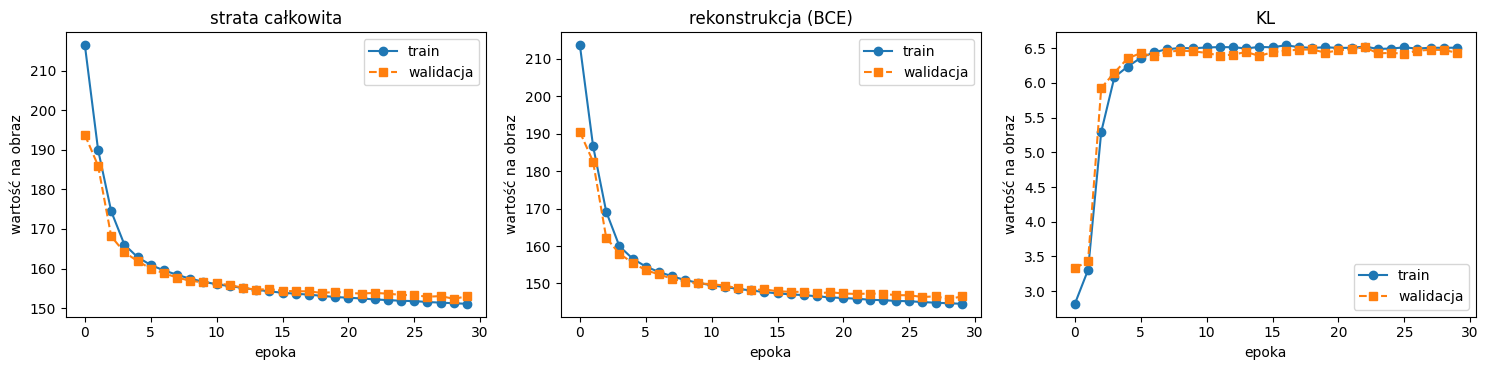

In [9]:
# Krzywe uczenia: oba składniki straty osobno
h = hist_vae.history
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, klucz, tyt in zip(ax, ["loss", "rec_loss", "kl_loss"], ["strata całkowita", "rekonstrukcja (BCE)", "KL"]):
    a.plot(h[klucz], "o-", label="train")
    a.plot(h["val_" + klucz], "s--", label="walidacja")
    a.set_title(tyt); a.set_xlabel("epoka"); a.set_ylabel("wartość na obraz"); a.legend()
plt.tight_layout(); plt.show()

**Co obserwować:** KL na początku zwykle **rośnie** (enkoder zaczyna kodować informację, odchodząc od $\mathcal{N}(0, I)$), a potem się stabilizuje; rekonstrukcja monotonicznie maleje. To naturalna "negocjacja" między dwoma składnikami. Jeśli KL spada do ok. 0 i tam zostaje - latent przestał nieść informację (*posterior collapse*), sprawdź skalę `rec_loss`.

### Przestrzeń latentna VAE i generowanie z siatki

Rysujemy `z_mean` dla obrazów testowych (bez losowania - to "środek" kodu obrazu). Następnie dekodujemy regularną siatkę punktów. Siatkę budujemy na **kwantylach rozkładu normalnego** (`norm.ppf`), bo a priori $\mathbf{z} \sim \mathcal{N}(0, I)$ - dzięki temu punkty są gęściej tam, gdzie leży większość masy prawdopodobieństwa.

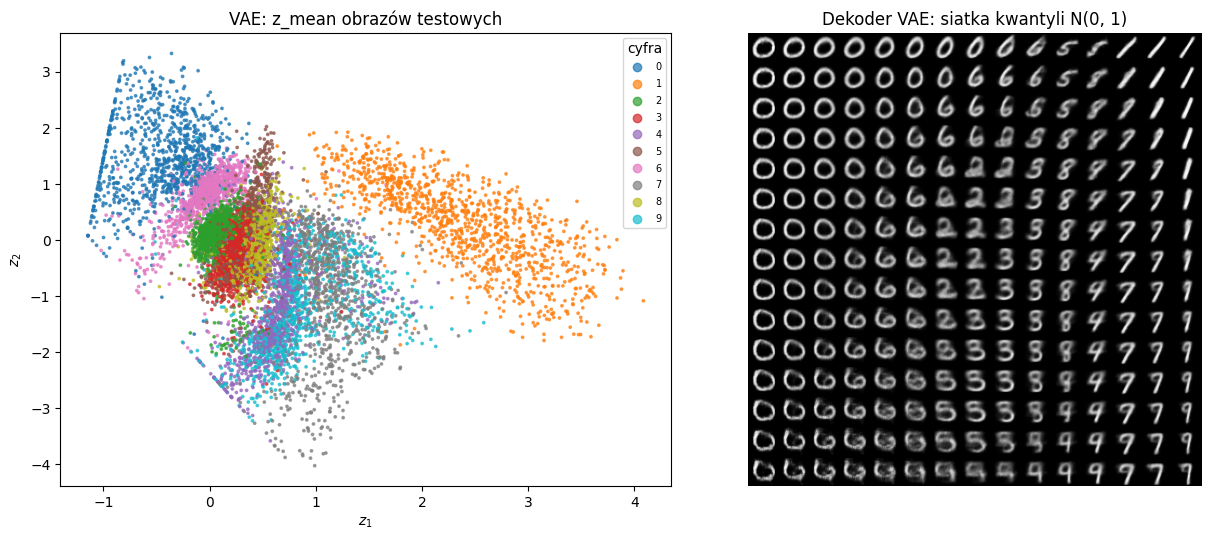

średnia z_mean: [ 0.58 -0.11] | odch. std.: [0.82 1.07] | średnie sigma: [0.035 0.065]


In [10]:
z_mean_te, z_log_var_te, _ = enc_vae.predict(x_mnist_te, verbose=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
sc = ax[0].scatter(z_mean_te[:, 0], z_mean_te[:, 1], c=y_mnist_te, cmap="tab10", s=3, alpha=0.7)
ax[0].legend(*sc.legend_elements(), title="cyfra", fontsize=7)
ax[0].set_xlabel("$z_1$"); ax[0].set_ylabel("$z_2$"); ax[0].set_title("VAE: z_mean obrazów testowych")

n = 15
siatka_z = np.array([[norm.ppf(a), norm.ppf(b)]
                     for b in np.linspace(0.95, 0.05, n) for a in np.linspace(0.05, 0.95, n)], dtype="float32")
gen = dec_vae.predict(siatka_z, verbose=0).reshape(n, n, 28, 28)
ax[1].imshow(gen.transpose(0, 2, 1, 3).reshape(n * 28, n * 28), cmap="gray")
ax[1].set_title("Dekoder VAE: siatka kwantyli N(0, 1)"); ax[1].axis("off")
plt.tight_layout(); plt.show()
print("średnia z_mean:", z_mean_te.mean(0).round(2), "| odch. std.:", z_mean_te.std(0).round(2),
      "| średnie sigma:", np.exp(0.5 * z_log_var_te).mean(0).round(3))

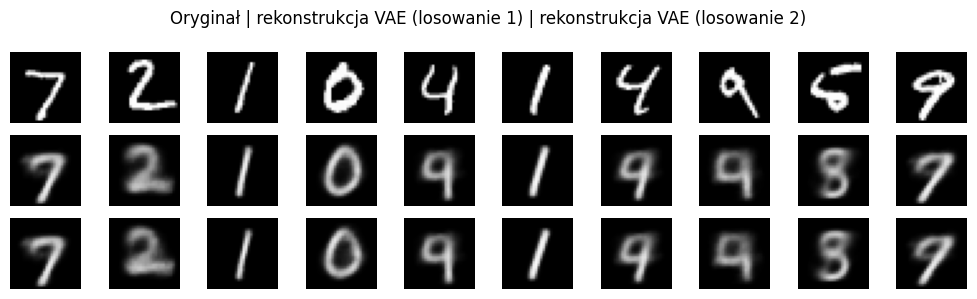

średnia różnica między dwoma losowaniami: 0.013469849713146687


In [11]:
# Rekonstrukcje VAE: każde wywołanie losuje inne z, więc ten sam obraz daje nieco różne wyniki
rek_1 = vae.predict(x_mnist_te[:10], verbose=0)
rek_2 = vae.predict(x_mnist_te[:10], verbose=0)
plansza(np.concatenate([x_mnist_te[:10], rek_1, rek_2]), 3, 10,
        "Oryginał | rekonstrukcja VAE (losowanie 1) | rekonstrukcja VAE (losowanie 2)")
print("średnia różnica między dwoma losowaniami:", float(np.abs(rek_1 - rek_2).mean()))

**Typowe błędy przy VAE:**
- strata rekonstrukcji uśredniona zamiast zsumowana po pikselach - KL dominuje, latent "zapada się",
- znak w KL (strata ujemna i rosnąca),
- `ops.exp(z_log_var)` zamiast `ops.exp(0.5 * z_log_var)` w próbkowaniu,
- wizualizacja `z` (losowe) zamiast `z_mean` - wykres jest "zaszumiony",
- brak właściwości `metrics` - wartości w logach kumulują się między epokami zamiast być resetowane.

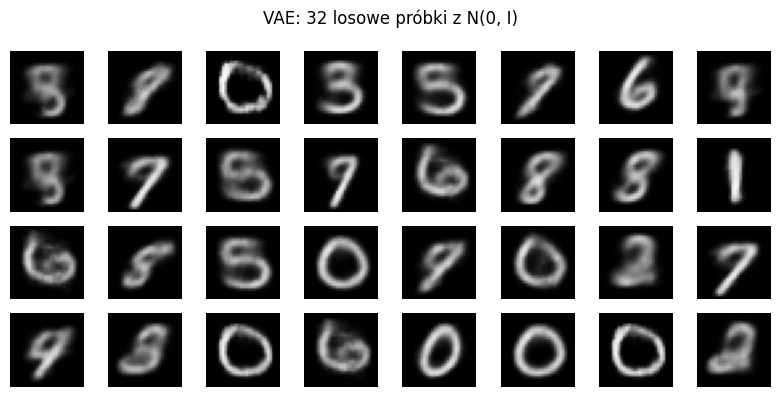

In [12]:
# Generowanie: losujemy z ~ N(0, I) - prawdziwy model generatywny
z_los = np.random.default_rng(SEED).normal(size=(32, LATENT_VAE)).astype("float32")
plansza(dec_vae.predict(z_los, verbose=0), 4, 8, "VAE: 32 losowe próbki z N(0, I)")

### Zadanie 2.3 - interpolacja: przestrzeń pikseli vs przestrzeń latentna

Weź dwa obrazy testowe różnych cyfr (np. pierwsze wystąpienie 1 i 8: `x_a`, `x_b`).
1. **Interpolacja w pikselach:** $(1-t)\mathbf{x}_a + t\,\mathbf{x}_b$ dla 10 wartości $t \in [0, 1]$.
2. **Interpolacja w latencie:** zakoduj oba obrazy (`z_mean`), interpoluj $\mathbf{z}_t = (1-t)\mathbf{z}_a + t\,\mathbf{z}_b$ i zdekoduj.
3. Narysuj oba wiersze (zmienne `wiersz_piksele`, `wiersz_latent` - tablice `(10, 28, 28)`).

**Kryteria sukcesu:** w pikselach widać "nałożenie dwóch obrazów" (przenikanie), w latencie - stopniową zmianę kształtu, każdy obraz pośredni wygląda jak (jakaś) cyfra.

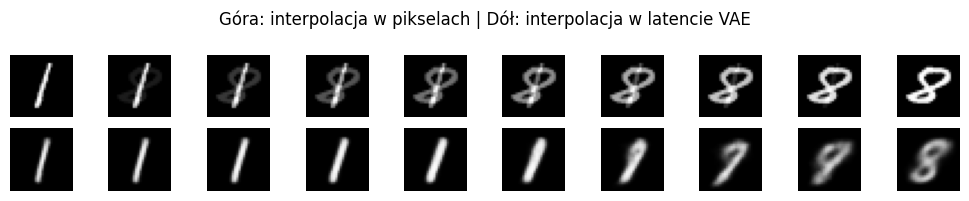

In [13]:
ts = np.linspace(0, 1, 10)
x_a = x_mnist_te[np.argmax(y_mnist_te == 1)]
x_b = x_mnist_te[np.argmax(y_mnist_te == 8)]
wiersz_piksele, wiersz_latent = None, None
# 1. Interpolacja w pikselach - "przenikanie" dwóch obrazów
wiersz_piksele = np.stack([(1 - t) * x_a + t * x_b for t in ts])[..., 0]               # (10, 28, 28)
# 2. Interpolacja w latencie: z_mean obu obrazów -> punkty pośrednie -> dekoder
zm_ab, _, _ = enc_vae.predict(np.stack([x_a, x_b]), verbose=0)
z_t = np.stack([(1 - t) * zm_ab[0] + t * zm_ab[1] for t in ts]).astype("float32")
wiersz_latent = dec_vae.predict(z_t, verbose=0)[..., 0]                                 # (10, 28, 28)
if wiersz_piksele is not None:
    plansza(np.concatenate([np.reshape(wiersz_piksele, (10, 28, 28)), np.reshape(wiersz_latent, (10, 28, 28))]),
            2, 10, "Góra: interpolacja w pikselach | Dół: interpolacja w latencie VAE")

### Zadanie 2.4 - hipoteza: wpływ wagi KL ($\beta$)

**Hipoteza (UGŁ_U01):** *zwiększenie $\beta$ poprawia regularność przestrzeni latentnej (kody bliższe $\mathcal{N}(0,I)$) kosztem jakości rekonstrukcji; zmniejszenie $\beta$ działa odwrotnie.*

1. Wytrenuj trzy VAE (nowe enkodery i dekodery!) z $\beta \in \{0.1, 1, 4\}$ przez `EPOKI_KROTKO` epok.
2. Dla każdego zapisz w `wyniki_beta` (lista słowników): `beta`, końcowe `rec_loss`, `kl_loss` (z historii) oraz odchylenie standardowe `z_mean` na teście.
3. Narysuj trzy wykresy przestrzeni latentnej obok siebie.
4. Napisz 2-3 zdania wniosku: czy hipoteza się potwierdziła?

**Wskazówka:** ponieważ `rec_loss` jest sumą po 784 pikselach, $\beta = 4$ to wciąż umiarkowana regularyzacja; przy $\beta \to 0$ VAE zbliża się do zwykłego AE.

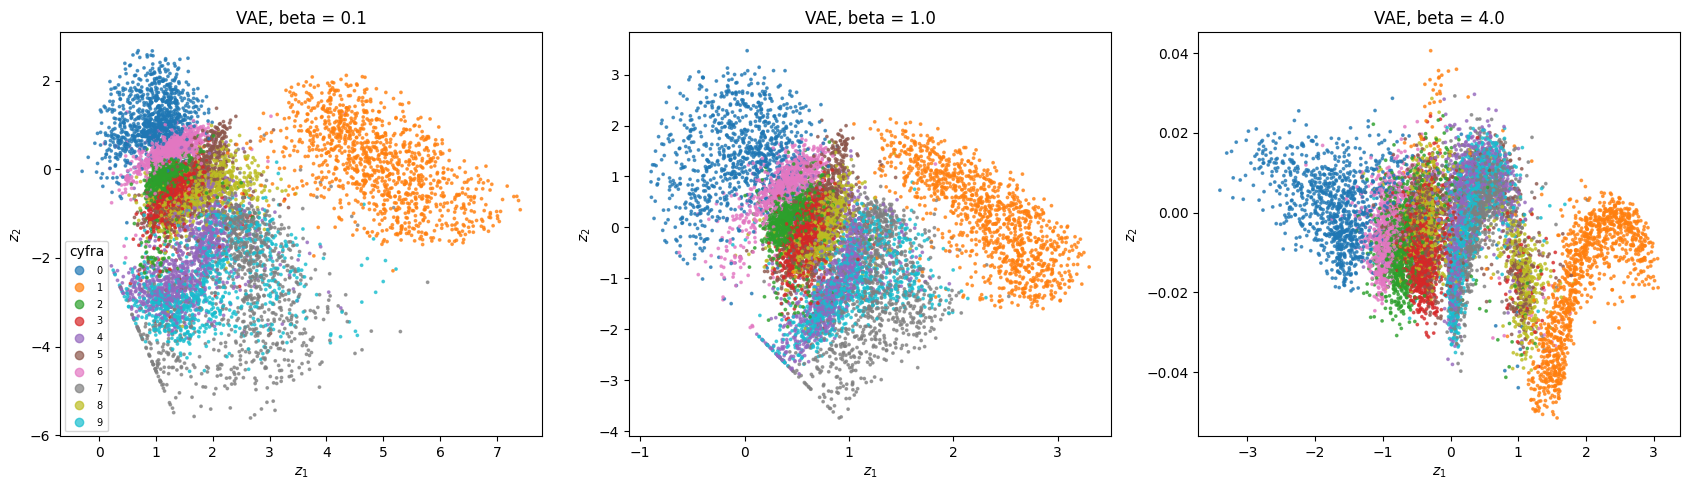

,beta,rec_loss,kl_loss,std z_mean (z1),std z_mean (z2)
0,0.1,147.835,12.644,1.263,1.410
1,1.0,150.296,6.478,0.675,1.057
2,4.0,170.330,2.508,1.036,0.012


In [14]:
wyniki_beta = []
z_beta = {}
for beta in [0.1, 1.0, 4.0]:
    keras.utils.set_random_seed(SEED)
    vae_b = VAE(zbuduj_enkoder_vae(), zbuduj_dekoder_vae(), beta=beta)     # NOWE enkoder i dekoder
    vae_b.compile(optimizer=keras.optimizers.Adam(1e-3))
    h_b = vae_b.fit(x_mnist, epochs=EPOKI_KROTKO, batch_size=128, verbose=0).history
    zm_b, _, _ = vae_b.enkoder.predict(x_mnist_te, verbose=0)
    z_beta[beta] = zm_b
    wyniki_beta.append({"beta": beta, "rec_loss": h_b["rec_loss"][-1], "kl_loss": h_b["kl_loss"][-1],
                        "std z_mean (z1)": zm_b[:, 0].std(), "std z_mean (z2)": zm_b[:, 1].std()})

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (beta, zm_b) in zip(axes, z_beta.items()):
    sc = ax.scatter(zm_b[:, 0], zm_b[:, 1], c=y_mnist_te, cmap="tab10", s=3, alpha=0.7)
    ax.set_title(f"VAE, beta = {beta}"); ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$")
axes[0].legend(*sc.legend_elements(), title="cyfra", fontsize=7)
plt.tight_layout(); plt.show()
# Wniosek: wraz ze wzrostem beta rośnie rec_loss (gorsza rekonstrukcja), a maleje kl_loss - kody są bliżej
# N(0, I) (odchylenie z_mean zbliża się do 1 lub poniżej, skupienia bardziej się nakładają). Dla beta = 0.1
# rekonstrukcja jest najlepsza, ale latent jest szeroko rozrzucony (std >> 1) i ma "dziury" jak zwykły AE.
# Jeśli tabela pokazuje ten trend, hipoteza się potwierdza.
display(pd.DataFrame(wyniki_beta).round(3))

## 3. GAN - generatywne sieci przeciwstawne (DCGAN)

### Teoria (W5)

Dwie sieci grają w grę o sumie zerowej:
- **generator** $G_\theta(\mathbf{z})$, $\mathbf{z} \sim \mathcal{N}(0, I)$ - tworzy obraz,
- **dyskryminator** $D_\psi(\mathbf{x}) \in (0,1)$ - prawdopodobieństwo, że obraz jest prawdziwy.

$$\min_G \max_D \; V(D, G) = \mathbb{E}_{\mathbf{x}\sim p_{dane}}[\log D(\mathbf{x})] + \mathbb{E}_{\mathbf{z}\sim p(\mathbf{z})}[\log(1 - D(G(\mathbf{z})))].$$

W optimum (Goodfellow i in., 2014) $p_G = p_{dane}$ i $D \equiv 1/2$. W praktyce trenujemy **naprzemiennie**:
1. **Krok D:** maksymalizuj $\log D(\mathbf{x}) + \log(1 - D(G(\mathbf{z})))$, czyli BCE z etykietą 1 dla prawdziwych i 0 dla fałszywych.
2. **Krok G:** zamiast minimalizować $\log(1 - D(G(\mathbf{z})))$ (gradient zanika, gdy D łatwo wygrywa), **maksymalizujemy $\log D(G(\mathbf{z}))$** - tzw. *non-saturating loss*. W kodzie: BCE fałszywych obrazów z etykietą **1**.

Dyskryminator zwraca **logity** (bez sigmoidy), a strata to `BinaryCrossentropy(from_logits=True)` - numerycznie stabilniej.

**Zasady DCGAN (Radford i in., 2015):** splot ze stride zamiast poolingu, `Conv2DTranspose` w G, BatchNorm w G, `LeakyReLU(0.2)` w D, `tanh` na wyjściu G (dlatego dane w $[-1, 1]$), Adam z lr = 2e-4 i $\beta_1 = 0.5$.

**Typowe problemy:**
- **mode collapse** - G produkuje tylko kilka rodzajów obrazów, które dobrze oszukują D,
- **niestabilność / oscylacje** - straty skaczą, jakość próbek pogarsza się po pewnym czasie,
- **D za silny** - strata D -> 0, gradient dla G zanika. Pomaga: *label smoothing* (etykieta 0.9 zamiast 1 dla prawdziwych), Dropout w D, mniejsze lr D.

**Ważne:** strata G i D **nie mówi**, czy obrazy są dobre (to gra, a nie minimalizacja jednej funkcji). Jakość oceniamy wzrokowo i metrykami typu FID.

In [15]:
def zbuduj_dyskryminator():
    wej = keras.Input(shape=(28, 28, 1))
    h = layers.Conv2D(64, 4, strides=2, padding="same")(wej)          # 14x14x64
    h = layers.LeakyReLU(negative_slope=0.2)(h)
    h = layers.Conv2D(128, 4, strides=2, padding="same")(h)           # 7x7x128
    h = layers.LeakyReLU(negative_slope=0.2)(h)
    h = layers.Flatten()(h)
    h = layers.Dropout(0.3)(h)                                        # osłabia D, stabilizuje grę
    logit = layers.Dense(1)(h)                                        # logit (bez sigmoidy!)
    return keras.Model(wej, logit, name="dyskryminator")

D = zbuduj_dyskryminator()
D.summary()

Model: "dyskryminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

### Zadanie 3.1 - generator DCGAN

Uzupełnij `zbuduj_generator(latent_dim)`:
- `Dense(7*7*128, use_bias=False)` -> `BatchNormalization` -> `LeakyReLU(0.2)` -> `Reshape((7, 7, 128))`,
- `Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False)` -> `BatchNormalization` -> `LeakyReLU(0.2)` (14x14),
- `Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh")` (28x28x1).

`use_bias=False` przed BatchNorm, bo BN i tak ma własne przesunięcie $\beta$ - bias byłby zbędnym parametrem.

**Kryteria sukcesu:** `G.output_shape == (None, 28, 28, 1)`, wartości wyjścia w $(-1, 1)$; `D(G(z))` daje tensor `(batch, 1)`.

In [16]:
def zbuduj_generator(latent_dim=LATENT_GAN):
    wej = keras.Input(shape=(latent_dim,))
    h = layers.Dense(7 * 7 * 128, use_bias=False)(wej)
    h = layers.BatchNormalization()(h)
    h = layers.LeakyReLU(negative_slope=0.2)(h)
    h = layers.Reshape((7, 7, 128))(h)
    h = layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False)(h)       # 14x14x64
    h = layers.BatchNormalization()(h)
    h = layers.LeakyReLU(negative_slope=0.2)(h)
    wyj = layers.Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh")(h)   # 28x28x1 w (-1, 1)
    return keras.Model(wej, wyj, name="generator")

G = zbuduj_generator()
G.summary()
z_test = keras.random.normal((4, LATENT_GAN), seed=SEED)
print("G(z):", G(z_test).shape, "| D(G(z)):", D(G(z_test)).shape)

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6272)           │       802,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_4 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 960,257 (3.66 MB)

 Trainable params: 947,585 (3.61 MB)

 Non-trainable params: 12,672 (49.50 KB)

G(z): (4, 28, 28, 1) | D(G(z)): (4, 1)


### Zadanie 3.2 - `train_step` GAN-a (Keras 3)

Klasa `GAN` przechowuje G, D, dwa optymalizatory i funkcję straty. Uzupełnij w `train_step`:

**Krok D** (w `tf.GradientTape`):
- wygeneruj `fake = self.generator(z, training=True)`,
- policz logity `D(real)` i `D(fake)` (z `training=True`),
- `d_loss = loss_fn(0.9 * jedynki, logity_real) + loss_fn(zera, logity_fake)` (label smoothing 0.9),
- gradient **tylko po wagach D** i krok `self.d_optimizer`.

**Krok G** (nowe $\mathbf{z}$, nowa taśma):
- `g_loss = loss_fn(jedynki, D(G(z)))` (non-saturating),
- gradient **tylko po wagach G** i krok `self.g_optimizer`.

Dodatkowo aktualizujemy diagnostyki: średnie $D(\mathbf{x})$ i $D(G(\mathbf{z}))$ po sigmoidzie (`ops.sigmoid`).

**Kryteria sukcesu:** trening się wykonuje; w pełnym trybie `d_loss` ok. 1.1-1.4, `g_loss` ok. 0.8-1.5 (oscyluje), $D(\mathbf{x})$ ok. 0.6-0.7, $D(G(\mathbf{z}))$ ok. 0.3-0.4. Jeśli `d_loss` -> 0, a `g_loss` rośnie bez końca - D wygrał.

**Uwaga Keras 3:** nadpisując `compile`, wywołaj `super().compile()`. Optymalizatory "budujemy" jawnie (`build`) na zmiennych odpowiedniej sieci - wtedy ich stan powstaje przed kompilacją `tf.function`.

In [17]:
class GAN(keras.Model):
    def __init__(self, generator, discriminator, latent_dim, **kwargs):
        super().__init__(**kwargs)
        self.generator, self.discriminator, self.latent_dim = generator, discriminator, latent_dim
        self.seed_generator = keras.random.SeedGenerator(SEED)
        self.d_loss_tracker = keras.metrics.Mean(name="d_loss")
        self.g_loss_tracker = keras.metrics.Mean(name="g_loss")
        self.d_real_tracker = keras.metrics.Mean(name="D_real")   # średnie D(x) - prawdziwe
        self.d_fake_tracker = keras.metrics.Mean(name="D_fake")   # średnie D(G(z)) - fałszywe

    def compile(self, d_optimizer, g_optimizer, loss_fn):
        super().compile()
        self.d_optimizer, self.g_optimizer, self.loss_fn = d_optimizer, g_optimizer, loss_fn
        self.d_optimizer.build(self.discriminator.trainable_variables)
        self.g_optimizer.build(self.generator.trainable_variables)

    @property
    def metrics(self):
        return [self.d_loss_tracker, self.g_loss_tracker, self.d_real_tracker, self.d_fake_tracker]

    def train_step(self, real):
        if isinstance(real, (tuple, list)):
            real = real[0]
        batch = ops.shape(real)[0]
        jedynki = ops.ones((batch, 1))
        zera = ops.zeros((batch, 1))

        # ---- Krok D ----
        z = keras.random.normal((batch, self.latent_dim), seed=self.seed_generator)
        with tf.GradientTape() as tape:
            fake = self.generator(z, training=True)
            logit_real = self.discriminator(real, training=True)
            logit_fake = self.discriminator(fake, training=True)
            d_loss = (self.loss_fn(0.9 * jedynki, logit_real)      # label smoothing dla prawdziwych
                      + self.loss_fn(zera, logit_fake))
        d_grads = tape.gradient(d_loss, self.discriminator.trainable_weights)          # TYLKO wagi D
        self.d_optimizer.apply_gradients(zip(d_grads, self.discriminator.trainable_weights))

        # ---- Krok G ----
        z = keras.random.normal((batch, self.latent_dim), seed=self.seed_generator)
        with tf.GradientTape() as tape:
            logit_gen = self.discriminator(self.generator(z, training=True), training=True)
            g_loss = self.loss_fn(jedynki, logit_gen)              # non-saturating: fałszywe z etykietą 1
        g_grads = tape.gradient(g_loss, self.generator.trainable_weights)              # TYLKO wagi G
        self.g_optimizer.apply_gradients(zip(g_grads, self.generator.trainable_weights))

        self.d_loss_tracker.update_state(d_loss)
        self.g_loss_tracker.update_state(g_loss)
        self.d_real_tracker.update_state(ops.mean(ops.sigmoid(logit_real)))
        self.d_fake_tracker.update_state(ops.mean(ops.sigmoid(logit_fake)))
        return {m.name: m.result() for m in self.metrics}

### Monitorowanie postępu: callback z próbkami po epokach

Ponieważ straty GAN-a słabo odzwierciedlają jakość, zapisujemy próbki z **ustalonego** wektora szumu po każdej epoce. Ten sam $\mathbf{z}$ pozwala zobaczyć, jak zmienia się "ten sam" obraz w czasie treningu.

Dane podajemy jako `tf.data.Dataset` z `drop_remainder=True` - wszystkie batche mają ten sam rozmiar (mniej rekompilacji, stabilniejsza BatchNorm).

In [18]:
class MonitorGAN(keras.callbacks.Callback):
    # Po każdej epoce zapisuje 16 próbek z tego samego (ustalonego) szumu
    def __init__(self, latent_dim, n=16):
        super().__init__()
        self.z = keras.random.normal((n, latent_dim), seed=123)
        self.migawki = []
    def on_epoch_end(self, epoch, logs=None):
        obr = ops.convert_to_numpy(self.model.generator(self.z, training=False))
        self.migawki.append(obr)

BATCH_GAN = 64 if SZYBKI_TRYB else 128
ds_gan = (tf.data.Dataset.from_tensor_slices(x_fash)
          .shuffle(len(x_fash), seed=SEED)
          .batch(BATCH_GAN, drop_remainder=True)
          .prefetch(tf.data.AUTOTUNE))

G = zbuduj_generator(); D = zbuduj_dyskryminator()     # świeże sieci
gan = GAN(G, D, LATENT_GAN)
gan.compile(d_optimizer=keras.optimizers.Adam(2e-4, beta_1=0.5),
            g_optimizer=keras.optimizers.Adam(2e-4, beta_1=0.5),
            loss_fn=keras.losses.BinaryCrossentropy(from_logits=True))
monitor = MonitorGAN(LATENT_GAN)

t0 = time.time()
hist_gan = gan.fit(ds_gan, epochs=EPOKI_GAN, callbacks=[monitor], shuffle=False, verbose=2)   # tasowanie robi już tf.data
print(f"Czas treningu GAN: {time.time() - t0:.1f} s")

Epoch 1/30
468/468 - 19s - 40ms/step - D_fake: 0.4191 - D_real: 0.5124 - d_loss: 1.2549 - g_loss: 0.9285
Epoch 2/30
468/468 - 6s - 13ms/step - D_fake: 0.3514 - D_real: 0.5462 - d_loss: 1.1163 - g_loss: 1.1432
Epoch 3/30
468/468 - 6s - 13ms/step - D_fake: 0.3287 - D_real: 0.5719 - d_loss: 1.0851 - g_loss: 1.2237
Epoch 4/30
468/468 - 6s - 13ms/step - D_fake: 0.3427 - D_real: 0.5580 - d_loss: 1.1293 - g_loss: 1.1479
Epoch 5/30
468/468 - 6s - 14ms/step - D_fake: 0.3627 - D_real: 0.5380 - d_loss: 1.1787 - g_loss: 1.0781
Epoch 6/30
468/468 - 6s - 13ms/step - D_fake: 0.3781 - D_real: 0.5224 - d_loss: 1.2177 - g_loss: 1.0376
Epoch 7/30
468/468 - 6s - 13ms/step - D_fake: 0.3874 - D_real: 0.5122 - d_loss: 1.2369 - g_loss: 1.0028
Epoch 8/30
468/468 - 6s - 13ms/step - D_fake: 0.3935 - D_real: 0.5062 - d_loss: 1.2517 - g_loss: 0.9870
Epoch 9/30
468/468 - 6s - 13ms/step - D_fake: 0.3956 - D_real: 0.5040 - d_loss: 1.2552 - g_loss: 0.9777
Epoch 10/30
468/468 - 6s - 13ms/step - D_fake: 0.3969 - D_real:

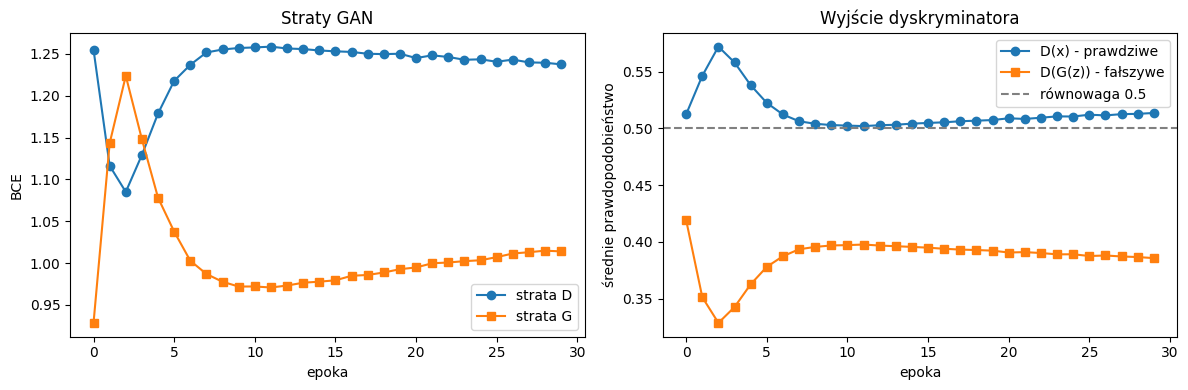

In [19]:
# Straty i diagnostyki D(x), D(G(z)) w kolejnych epokach
h = hist_gan.history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["d_loss"], "o-", label="strata D"); ax[0].plot(h["g_loss"], "s-", label="strata G")
ax[0].set_xlabel("epoka"); ax[0].set_ylabel("BCE"); ax[0].set_title("Straty GAN"); ax[0].legend()
ax[1].plot(h["D_real"], "o-", label="D(x) - prawdziwe"); ax[1].plot(h["D_fake"], "s-", label="D(G(z)) - fałszywe")
ax[1].axhline(0.5, color="gray", ls="--", label="równowaga 0.5")
ax[1].set_xlabel("epoka"); ax[1].set_ylabel("średnie prawdopodobieństwo"); ax[1].set_title("Wyjście dyskryminatora")
ax[1].legend(); plt.tight_layout(); plt.show()

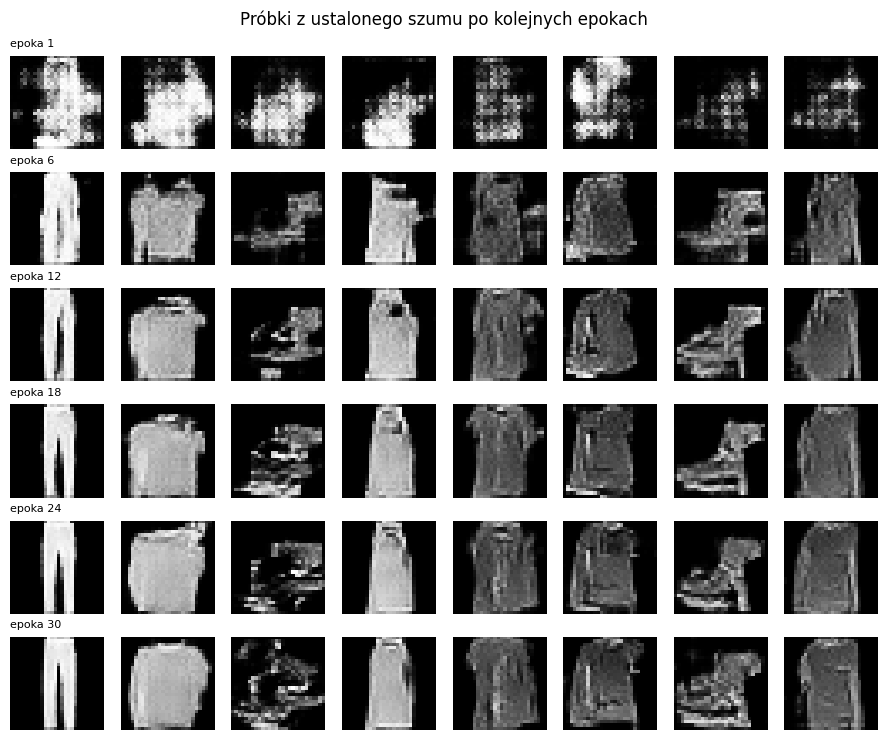

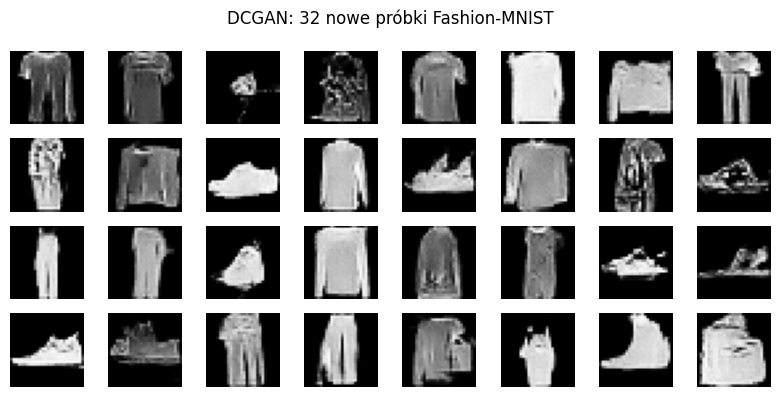

In [20]:
# Ewolucja tych samych próbek w czasie treningu (wiersz = wybrana epoka)
epoki_do_pokazu = sorted(set(np.linspace(0, len(monitor.migawki) - 1, min(6, len(monitor.migawki))).astype(int)))
fig, axes = plt.subplots(len(epoki_do_pokazu), 8, figsize=(9, 1.25 * len(epoki_do_pokazu)))
axes = np.atleast_2d(axes)
for r, e in enumerate(epoki_do_pokazu):
    for c in range(8):
        axes[r, c].imshow(monitor.migawki[e][c, :, :, 0], cmap="gray", vmin=-1, vmax=1); axes[r, c].axis("off")
    axes[r, 0].set_title(f"epoka {e + 1}", fontsize=8, loc="left")
fig.suptitle("Próbki z ustalonego szumu po kolejnych epokach"); plt.tight_layout(); plt.show()

plansza(ops.convert_to_numpy(G(keras.random.normal((32, LATENT_GAN), seed=7), training=False)), 4, 8,
        "DCGAN: 32 nowe próbki Fashion-MNIST", zakres=(-1, 1))

### Zadanie 3.3 - interpolacja w przestrzeni szumu GAN (liniowa i sferyczna)

Przestrzeń $\mathbf{z}$ GAN-a też jest ciągła. Wylosuj dwa wektory $\mathbf{z}_a, \mathbf{z}_b$ i wygeneruj 10 obrazów pośrednich na dwa sposoby:
1. **liniowo:** $\mathbf{z}_t = (1-t)\mathbf{z}_a + t\mathbf{z}_b$,
2. **sferycznie (slerp):** $\mathbf{z}_t = \frac{\sin((1-t)\Omega)}{\sin\Omega}\mathbf{z}_a + \frac{\sin(t\Omega)}{\sin\Omega}\mathbf{z}_b$, gdzie $\cos\Omega = \frac{\mathbf{z}_a\cdot\mathbf{z}_b}{\lVert\mathbf{z}_a\rVert\lVert\mathbf{z}_b\rVert}$.

Dlaczego slerp? W wysokim wymiarze prawie cała masa $\mathcal{N}(0, I)$ leży na "skorupie" o promieniu $\approx\sqrt{d}$. Środek odcinka między dwoma losowymi punktami ma normę ok. $\sqrt{d/2}$ - to obszar, którego generator prawie nie widział podczas treningu. Slerp idzie po skorupie.

Zapisz normy pośrednich wektorów (`normy_lin`, `normy_slerp`) i narysuj je na wykresie oraz oba wiersze obrazów.

**Kryteria sukcesu:** norma interpolacji liniowej "zapada się" w środku (ok. $0.71\sqrt{d}$), slerp utrzymuje ją ok. $\sqrt{d}$.

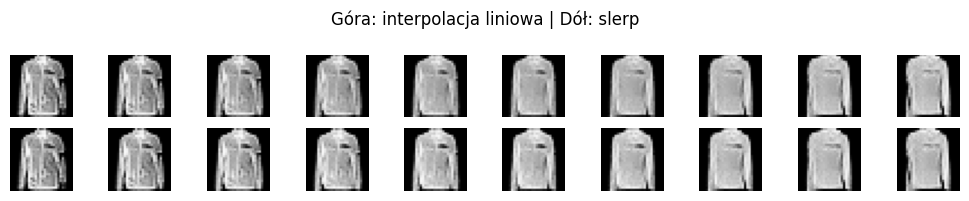

norma w środku: liniowa 7.90, slerp 11.36, sqrt(d) = 11.31


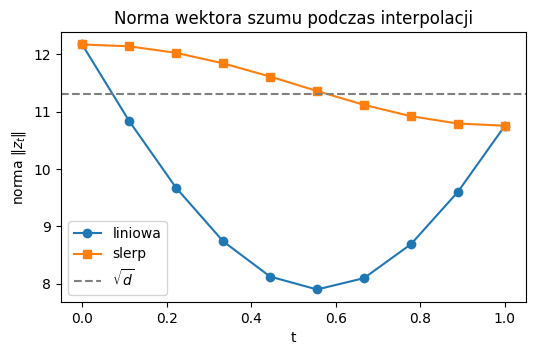

In [21]:
def slerp(za, zb, t):
    # Interpolacja sferyczna między wektorami za i zb
    omega = np.arccos(np.clip(np.dot(za, zb) / (np.linalg.norm(za) * np.linalg.norm(zb)), -1, 1))
    if np.isclose(omega, 0):
        return (1 - t) * za + t * zb
    return np.sin((1 - t) * omega) / np.sin(omega) * za + np.sin(t * omega) / np.sin(omega) * zb

rng = np.random.default_rng(3)
z_a, z_b = rng.normal(size=LATENT_GAN), rng.normal(size=LATENT_GAN)
ts = np.linspace(0, 1, 10)
normy_lin, normy_slerp = [], []
z_lin = np.stack([(1 - t) * z_a + t * z_b for t in ts]).astype("float32")
z_sl = np.stack([slerp(z_a, z_b, t) for t in ts]).astype("float32")
normy_lin = list(np.linalg.norm(z_lin, axis=1))
normy_slerp = list(np.linalg.norm(z_sl, axis=1))
obr_lin = ops.convert_to_numpy(G(z_lin, training=False))
obr_sl = ops.convert_to_numpy(G(z_sl, training=False))
plansza(np.concatenate([obr_lin, obr_sl]), 2, 10, "Góra: interpolacja liniowa | Dół: slerp", zakres=(-1, 1))
print(f"norma w środku: liniowa {normy_lin[len(ts) // 2]:.2f}, slerp {normy_slerp[len(ts) // 2]:.2f}, "
      f"sqrt(d) = {np.sqrt(LATENT_GAN):.2f}")
plt.figure(figsize=(6, 3.5))
plt.plot(ts, normy_lin, "o-", label="liniowa"); plt.plot(ts, normy_slerp, "s-", label="slerp")
plt.axhline(np.sqrt(LATENT_GAN), color="gray", ls="--", label="$\\sqrt{d}$")
plt.xlabel("t"); plt.ylabel("norma $\\|z_t\\|$"); plt.title("Norma wektora szumu podczas interpolacji"); plt.legend(); plt.show()

### Zadanie 3.4 - czy mamy mode collapse? Pomiar różnorodności klasyfikatorem

Wzrokowa ocena jest subiektywna. Prosty, ilościowy sposób (idea zbliżona do *Inception Score*): wytrenuj klasyfikator Fashion-MNIST i sprawdź, **jak rozkładają się klasy wygenerowanych obrazów**. Zdrowy GAN generuje wszystkie 10 klas mniej więcej po równo; przy mode collapse dominuje kilka klas.

1. Klasyfikator (gotowy kod poniżej) - uruchom i sprawdź dokładność na teście.
2. Wygeneruj `N_GEN` obrazów, sklasyfikuj je, policz histogram klas i **znormalizowaną entropię** rozkładu klas $H = -\frac{1}{\log 10}\sum_c p_c \log p_c$ ($H=1$ - idealnie równo, $H\to0$ - jedna klasa). Zapisz w `entropia_gen`.
3. Policz średnią maksymalną pewność klasyfikatora na próbkach (`pewnosc_gen`) - niska oznacza obrazy "niepodobne do niczego".
4. Porównaj z tymi samymi miarami dla prawdziwych obrazów testowych (`entropia_real`, `pewnosc_real`).

In [22]:
# Klasyfikator Fashion-MNIST (dane w [-1, 1], jak w GAN); warstwa "cechy" przyda się do FID w zadaniu dodatkowym
wej = keras.Input(shape=(28, 28, 1))
h = layers.Conv2D(32, 3, activation="relu", padding="same")(wej)
h = layers.MaxPooling2D()(h)
h = layers.Conv2D(64, 3, activation="relu", padding="same")(h)
h = layers.MaxPooling2D()(h)
h = layers.Flatten()(h)
cechy = layers.Dense(64, activation="relu", name="cechy")(h)
wyj = layers.Dense(10, activation="softmax")(layers.Dropout(0.3)(cechy))
klasyfikator = keras.Model(wej, wyj, name="klasyfikator_fashion")
klasyfikator.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
klasyfikator.fit(x_fash, y_fash, epochs=1 if SZYBKI_TRYB else 5, batch_size=128, verbose=2)
print("Dokładność na teście:", round(klasyfikator.evaluate(x_fash_te, y_fash_te, verbose=0)[1], 3))

Epoch 1/5
469/469 - 13s - 28ms/step - accuracy: 0.7958 - loss: 0.5796
Epoch 2/5
469/469 - 3s - 5ms/step - accuracy: 0.8722 - loss: 0.3623
Epoch 3/5
469/469 - 2s - 5ms/step - accuracy: 0.8893 - loss: 0.3078
Epoch 4/5
469/469 - 2s - 5ms/step - accuracy: 0.8999 - loss: 0.2751
Epoch 5/5
469/469 - 2s - 5ms/step - accuracy: 0.9071 - loss: 0.2532
Dokładność na teście: 0.908


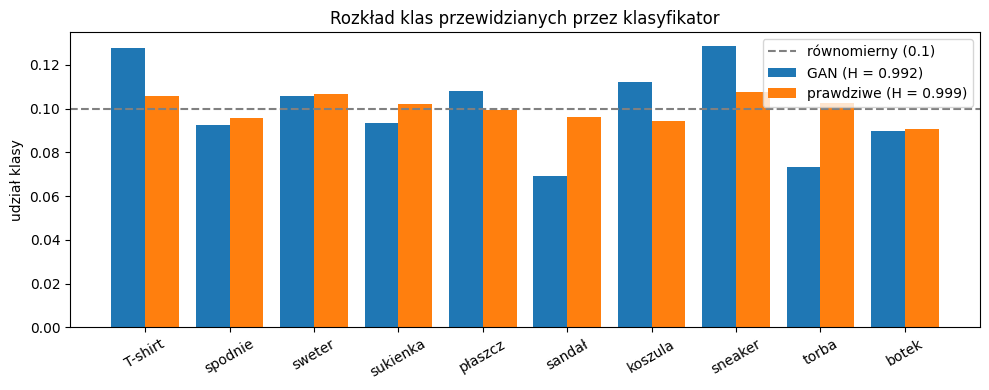

Entropia: GAN 0.992 | prawdziwe 0.999
Średnia pewność: GAN 0.785 | prawdziwe 0.918


In [23]:
N_GEN = 1000 if SZYBKI_TRYB else 5000
entropia_gen = pewnosc_gen = entropia_real = pewnosc_real = None

def entropia_znorm(p):
    # Znormalizowana entropia rozkładu klas (1 = równomierny)
    p = p[p > 0]
    return float(-(p * np.log(p)).sum() / np.log(10))

# Próbki GAN i ich klasyfikacja
z_gen = keras.random.normal((N_GEN, LATENT_GAN), seed=99)
x_gen = G.predict(ops.convert_to_numpy(z_gen), batch_size=256, verbose=0)
p_gen = klasyfikator.predict(x_gen, batch_size=256, verbose=0)
p_real = klasyfikator.predict(x_fash_te[:N_GEN], batch_size=256, verbose=0)

rozklad_gen = np.bincount(p_gen.argmax(1), minlength=10) / len(p_gen)
rozklad_real = np.bincount(p_real.argmax(1), minlength=10) / len(p_real)
entropia_gen, entropia_real = round(entropia_znorm(rozklad_gen), 3), round(entropia_znorm(rozklad_real), 3)
pewnosc_gen, pewnosc_real = round(float(p_gen.max(1).mean()), 3), round(float(p_real.max(1).mean()), 3)

x_pos = np.arange(10); w = 0.4
plt.figure(figsize=(10, 4))
plt.bar(x_pos - w / 2, rozklad_gen, w, label=f"GAN (H = {entropia_gen})")
plt.bar(x_pos + w / 2, rozklad_real, w, label=f"prawdziwe (H = {entropia_real})")
plt.axhline(0.1, c="gray", ls="--", label="równomierny (0.1)")
plt.xticks(x_pos, KLASY_FASHION, rotation=30); plt.ylabel("udział klasy")
plt.title("Rozkład klas przewidzianych przez klasyfikator"); plt.legend(); plt.tight_layout(); plt.show()
# Interpretacja: entropia bliska 1 (jak dla prawdziwych) oznacza brak mode collapse; wyraźnie niższa entropia
# i dominacja 1-3 klas - mode collapse. Niższa pewność dla GAN niż dla prawdziwych obrazów oznacza próbki
# mniej wyraźne / "pomiędzy" klasami.
print(f"Entropia: GAN {entropia_gen} | prawdziwe {entropia_real}")
print(f"Średnia pewność: GAN {pewnosc_gen} | prawdziwe {pewnosc_real}")

### Czy GAN zapamiętał dane treningowe? Test najbliższego sąsiada

Jeśli generator kopiuje obrazy treningowe, każda próbka ma "bliźniaka" w zbiorze uczącym. Dla kilku próbek szukamy najbliższego obrazu treningowego (odległość euklidesowa w przestrzeni cech klasyfikatora - bardziej semantyczna niż piksele) i wyświetlamy pary. Podobne, ale **nie identyczne** pary to dobry znak - model uogólnia.

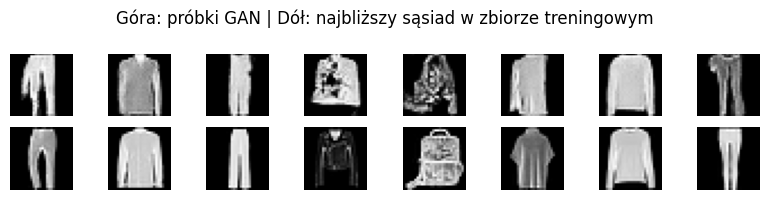

odległości do najbliższego sąsiada: [4.81 2.57 3.   4.91 7.41 3.87 1.98 4.45]


In [24]:
from sklearn.neighbors import NearestNeighbors
ekstr_nn = keras.Model(klasyfikator.input, klasyfikator.get_layer("cechy").output)   # cechy 64-wymiarowe
f_tr = ekstr_nn.predict(x_fash, verbose=0)
x_pr = ops.convert_to_numpy(G(keras.random.normal((8, LATENT_GAN), seed=21), training=False))
nn_model = NearestNeighbors(n_neighbors=1).fit(f_tr)
odl, idx = nn_model.kneighbors(ekstr_nn.predict(x_pr, verbose=0))
plansza(np.concatenate([x_pr, x_fash[idx[:, 0]]]), 2, 8,
        "Góra: próbki GAN | Dół: najbliższy sąsiad w zbiorze treningowym", zakres=(-1, 1))
print("odległości do najbliższego sąsiada:", odl[:, 0].round(2))

### Mode collapse i niestabilność - jak rozpoznać i co robić

| Objaw | Co widać | Typowe leki |
|---|---|---|
| Mode collapse | próbki prawie identyczne, niska entropia klas | minibatch discrimination, unrolled GAN, WGAN-GP, mniejsze lr G, restart |
| D wygrywa | `d_loss` -> 0, `D_fake` -> 0, `g_loss` rośnie | label smoothing, Dropout / szum w D, mniejsze lr D, mniej kroków D |
| G "oszukuje" słabego D | `D_fake` > 0.5 długo, obrazy słabe | większa pojemność D, więcej kroków D |
| Oscylacje | jakość próbek rośnie i spada | mniejsze lr, Adam z $\beta_1 = 0.5$, EMA wag G, zapis checkpointów i wybór najlepszego |

Zaawansowane warianty (W5): **WGAN / WGAN-GP** (odległość Wassersteina zamiast BCE - stabilniejsze gradienty), **spectral normalization** w D, **conditional GAN** (generowanie zadanej klasy), **StyleGAN**. Miara jakości: **FID** - odległość Frécheta między rozkładami cech (zwykle z sieci Inception) prawdziwych i wygenerowanych obrazów; im niższy, tym lepiej.

## 4. *(Opcjonalnie)* Ten sam GAN w PyTorch - wersja skrócona

Ta sekcja jest dla chętnych lub do domu. Pokazuje, że GAN to w istocie **dwie przeplatające się pętle optymalizacji**, które w PyTorch piszemy jawnie (W3). Architektura jest odpowiednikiem naszego DCGAN; różnice notacyjne:
- obrazy w formacie **NCHW** `(batch, 1, 28, 28)` (Keras: NHWC),
- `nn.ConvTranspose2d(k=4, s=2, p=1)` podwaja rozdzielczość: $H_{out} = (H-1)\cdot2 - 2\cdot1 + 4 = 2H$,
- `nn.BCEWithLogitsLoss` = sigmoid + BCE (odpowiednik `from_logits=True`),
- **`fake.detach()`** w kroku D - odcinamy graf, żeby gradient straty D nie płynął do G,
- `opt.zero_grad()` przed każdym `backward()`, bo PyTorch domyślnie **akumuluje** gradienty.

In [25]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

tfm = transforms.Compose([transforms.ToTensor(),                     # [0, 1], kształt (1, 28, 28)
                          transforms.Normalize((0.5,), (0.5,))])     # -> [-1, 1]
ds_t = datasets.FashionMNIST(root="./data", train=True, download=True, transform=tfm)
if SZYBKI_TRYB:
    ds_t = Subset(ds_t, range(2000))
loader = DataLoader(ds_t, batch_size=128, shuffle=True, drop_last=True, num_workers=2 if device == "cuda" else 0)
LAT_T = 64

class GenT(nn.Module):
    def __init__(self, latent=LAT_T):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(latent, 128 * 7 * 7, bias=False), nn.BatchNorm1d(128 * 7 * 7), nn.LeakyReLU(0.2))
        self.conv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.LeakyReLU(0.2),   # 14x14
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())                                            # 28x28
    def forward(self, z):
        return self.conv(self.fc(z).view(-1, 128, 7, 7))

class DisT(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2),       # 14x14
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2),     # 7x7
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(128 * 7 * 7, 1))   # logit
    def forward(self, x):
        return self.net(x)

G_t, D_t = GenT().to(device), DisT().to(device)
opt_G = torch.optim.Adam(G_t.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D_t.parameters(), lr=2e-4, betas=(0.5, 0.999))
kryterium = nn.BCEWithLogitsLoss()
print("parametry G:", sum(p.numel() for p in G_t.parameters()), "| D:", sum(p.numel() for p in D_t.parameters()))

PyTorch: 2.14.1+cu130 | urządzenie: cuda


100%|██████████| 26.4M/26.4M [00:00<00:00, 114MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 4.01MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 60.3MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 27.1MB/s]


parametry G: 546177 | D: 138561


### Zadanie 4.1 *(opcjonalne)* - pętla treningowa GAN w PyTorch

Uzupełnij ciało pętli po batchach:
1. **Krok D:** `fake = G_t(z)`; `loss_D = kryterium(D_t(real), 0.9·jedynki) + kryterium(D_t(fake.detach()), zera)`; `opt_D.zero_grad()`, `loss_D.backward()`, `opt_D.step()`.
2. **Krok G:** `loss_G = kryterium(D_t(fake), jedynki)`; `opt_G.zero_grad()`, `loss_G.backward()`, `opt_G.step()`.
3. Dopisz `loss_D.item()` i `loss_G.item()` do list `straty_D`, `straty_G`.

**Kryteria sukcesu:** straty w podobnym zakresie jak w Keras; po `EPOKI_TORCH` epokach (pełny tryb) widać rozpoznawalne ubrania.

**Pytanie:** co by się stało bez `.detach()`? (Podpowiedź: `loss_D.backward()` policzyłby gradienty także dla G i zużył graf obliczeniowy - drugi `backward` dla G zgłosiłby błąd lub G uczyłby się w złym kierunku przy kolejnym kroku.)

In [26]:
straty_D, straty_G = [], []
z_staly = torch.randn(16, LAT_T, device=device)    # ustalony szum do podglądu
t0 = time.time()
for epoka in range(EPOKI_TORCH):
    G_t.train(); D_t.train()
    for real, _ in loader:
        real = real.to(device)
        b = real.size(0)
        jedynki = torch.ones(b, 1, device=device)
        zera = torch.zeros(b, 1, device=device)
        z = torch.randn(b, LAT_T, device=device)
        # Krok D
        fake = G_t(z)
        loss_D = kryterium(D_t(real), 0.9 * jedynki) + kryterium(D_t(fake.detach()), zera)   # detach: bez gradientu do G
        opt_D.zero_grad()
        loss_D.backward()
        opt_D.step()
        # Krok G (non-saturating)
        loss_G = kryterium(D_t(fake), jedynki)
        opt_G.zero_grad()
        loss_G.backward()
        opt_G.step()
        straty_D.append(loss_D.item()); straty_G.append(loss_G.item())
    print(f"epoka {epoka + 1}/{EPOKI_TORCH}: D {np.mean(straty_D[-len(loader):]) if straty_D else float('nan'):.3f} | "
          f"G {np.mean(straty_G[-len(loader):]) if straty_G else float('nan'):.3f} | {time.time() - t0:.0f} s")

epoka 1/10: D 0.643 | G 3.406 | 16 s
epoka 2/10: D 1.106 | G 1.245 | 31 s
epoka 3/10: D 0.915 | G 1.516 | 47 s
epoka 4/10: D 0.866 | G 1.648 | 61 s
epoka 5/10: D 0.897 | G 1.623 | 77 s
epoka 6/10: D 0.959 | G 1.528 | 92 s
epoka 7/10: D 0.872 | G 2.485 | 107 s
epoka 8/10: D 1.000 | G 1.444 | 122 s
epoka 9/10: D 1.030 | G 1.362 | 138 s
epoka 10/10: D 1.038 | G 1.358 | 153 s


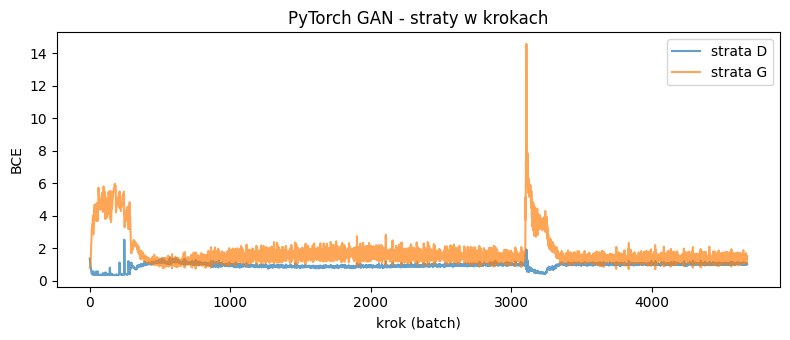

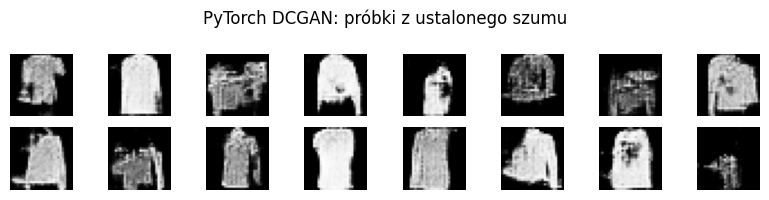

In [27]:
G_t.eval()
with torch.no_grad():                               # bez grafu obliczeń przy generowaniu
    probki_t = G_t(z_staly).cpu().numpy()           # (16, 1, 28, 28)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(straty_D, alpha=0.7, label="strata D"); ax.plot(straty_G, alpha=0.7, label="strata G")
ax.set_xlabel("krok (batch)"); ax.set_ylabel("BCE"); ax.set_title("PyTorch GAN - straty w krokach"); ax.legend()
plt.tight_layout(); plt.show()
plansza(probki_t, 2, 8, "PyTorch DCGAN: próbki z ustalonego szumu", zakres=(-1, 1))

## 5. Dalej niż GAN: modele dyfuzyjne i etyka (dyskusja, ok. 10 min)

**Modele dyfuzyjne (W5, zarys).** Proces "w przód" stopniowo dodaje szum gaussowski do obrazu przez $T$ kroków, aż powstanie czysty szum. Sieć (zwykle U-Net) uczy się **odwracać jeden krok** - przewidywać dodany szum $\boldsymbol\epsilon_\theta(\mathbf{x}_t, t)$, strata to proste MSE. Generowanie = start z szumu i $T$ kroków odszumiania. Związki z naszymi zajęciami:
- to uogólnienie **autoenkodera odszumiającego** z Lab 6 na wiele poziomów szumu,
- formalnie to hierarchiczny **VAE** z ustalonym enkoderem (procesem zaszumiania),
- w porównaniu z GAN: trening stabilny (jedna strata MSE, brak gry), wysoka różnorodność (brak mode collapse), ale wolne próbkowanie (wiele kroków).

**Etyka (UGŁ_K01).** Modele generatywne umożliwiają tworzenie **deepfake'ów** (podszywanie się pod osoby, dezinformacja, nadużycia wizerunku), mogą odtwarzać dane treningowe (prywatność, prawa autorskie) i powielać uprzedzenia obecne w danych. Odpowiedzi: znakowanie treści (watermarking, C2PA), detektory, przepisy (AI Act w UE - obowiązek oznaczania treści syntetycznych), dokumentowanie zbiorów i modeli.

**Pytania do dyskusji:**
1. Jak sprawdzić, czy nasz GAN nie "zapamiętał" obrazów treningowych? (wskazówka: najbliższy sąsiad w zbiorze treningowym)
2. Czy publikacja wytrenowanego generatora twarzy powinna wymagać ograniczeń? Jakich?

## 6. Sprawozdanie końcowe z laboratorium - instrukcja

Zgodnie z kartą przedmiotu ocena z laboratorium obejmuje **aktywność na zajęciach, wykonanie ćwiczeń i przesłanie sprawozdania podsumowującego po ostatnich zajęciach**. Ocena końcowa z przedmiotu = 60% kolokwium + 40% laboratorium (aktywność + sprawozdanie); obie części muszą być zaliczone pozytywnie.

### Termin i forma
- **Jedno sprawozdanie indywidualne** w formacie **PDF** (zalecane 10-15 stron bez załączników), przesłane w terminie i kanałem podanym przez prowadzącą.
- Do sprawozdania dołącz **link do notebooka Colab** z mini-projektem (udostępnienie "każdy, kto ma link - przeglądający") albo plik `.ipynb` **z zapisanymi wynikami komórek**.
- Nazwa pliku: `UG_Sprawozdanie_Nazwisko_Imie_nrIndeksu.pdf`.

### Wymagana struktura
1. **Strona tytułowa:** imię i nazwisko, nr indeksu, kierunek i semestr, nazwa kursu, prowadząca, data.
2. **Wybrane wyniki z Lab 3-7** (ok. 1-2 strony na laboratorium). W każdym laboratorium sekcja "Do sprawozdania końcowego" mówi, co pokazać. Każdy wykres musi mieć tytuł, opisane osie, legendę i **1-3 zdania interpretacji** (co widać, dlaczego, co z tego wynika).
3. **Mini-projekt - własny eksperyment** (najważniejsza część, ok. 4-6 stron):
   - **problem i zbiór danych** - wyłącznie zbiory używane na kursie (`keras.datasets`: MNIST, Fashion-MNIST, CIFAR-10; `sklearn.datasets`; `torchvision` MNIST/FashionMNIST) lub inne publiczne po uzgodnieniu z prowadzącą,
   - **hipoteza** sformułowana przed eksperymentem, w postaci sprawdzalnej, np. *"Autoenkoder konwolucyjny wykryje anomalie (klasa 'sandał') w Fashion-MNIST z wyższym ROC-AUC niż autoenkoder gęsty o tej samej liczbie parametrów"* (**UGŁ_U01**),
   - **metodyka** - architektura(y), hiperparametry, podział danych, metryki, baseline (np. model klasyczny lub prostszy model sieciowy), liczba powtórzeń (seedy),
   - **wyniki** - tabela i wykresy, najlepiej średnia ± odchylenie standardowe z co najmniej 3 uruchomień,
   - **weryfikacja hipotezy** - potwierdzona / odrzucona / częściowo, z uzasadnieniem liczbowym,
   - **propozycja usprawnienia** opartego na istniejących bibliotekach (np. inna architektura, regularyzacja, augmentacja, transfer learning, tuning KerasTuner/Optuna), **najlepiej sprawdzona eksperymentalnie** (**UGŁ_U02**).
4. **Wnioski i ograniczenia** (0,5-1 strona): co się udało, czego nie wiemy, co zrobiłbyś dalej.
5. **Bibliografia:** co najmniej 3 pozycje, w tym min. 1 z literatury przedmiotu i min. 1 artykuł naukowy lub dokumentacja (keras.io, pytorch.org) - **UGŁ_K01**.
6. **Oświadczenie o samodzielności** i informacja o użyciu narzędzi AI (do czego, w jakim zakresie). Kod i tekst muszą być rozumiane przez autora - prowadząca może poprosić o krótkie omówienie.

### Przykładowe tematy mini-projektu
- VAE vs AE vs PCA jako ekstraktor cech dla k-means na Fashion-MNIST (ARI/NMI).
- Wpływ $\beta$ i wymiaru latentu VAE na jakość rekonstrukcji i różnorodność próbek.
- DCGAN vs DCGAN z innymi technikami stabilizacji (label smoothing, spectral norm, różne lr D i G) - porównanie entropii klas / FID-lite.
- Transfer learning vs CNN od zera na podzbiorach CIFAR-10 różnej wielkości (krzywa uczenia w funkcji liczby danych).
- Sieć MLP (PyTorch) vs HistGradientBoosting na `fetch_california_housing` lub `load_breast_cancer` z walidacją krzyżową i analizą wycieku danych.

### Checklista przed wysłaniem sprawozdania

**Forma**
- [ ] PDF z poprawną nazwą pliku, strona tytułowa kompletna
- [ ] link do notebooka Colab działa (sprawdzone w trybie incognito) lub dołączony `.ipynb` z wynikami
- [ ] notebook wykonuje się od początku do końca (Środowisko wykonawcze -> Uruchom wszystko) bez błędów
- [ ] seedy ustawione, wersje bibliotek podane (komórka poniżej)

**Treść z Lab 3-7**
- [ ] z każdego laboratorium 3-7 co najmniej jeden wynik zgodny z sekcją "Do sprawozdania końcowego"
- [ ] wszystkie wykresy mają tytuł, opisy osi, legendę i interpretację w tekście
- [ ] liczby w tabelach mają jednostki / nazwy metryk i rozsądną liczbę cyfr znaczących

**Mini-projekt**
- [ ] hipoteza sformułowana wprost, **przed** opisem wyników
- [ ] jest baseline i uczciwe porównanie (ten sam podział danych, podobny budżet treningu)
- [ ] brak wycieku danych: skalowanie / PCA / wybór progu dopasowane tylko na zbiorze treningowym (walidacyjnym)
- [ ] zbiór testowy użyty tylko do końcowej oceny, nie do wyboru hiperparametrów
- [ ] wyniki z kilku uruchomień (średnia ± odch. std.) lub uzasadnienie, dlaczego jedno
- [ ] jasna odpowiedź: hipoteza potwierdzona / odrzucona / częściowo - z liczbami
- [ ] propozycja usprawnienia (UGŁ_U02), najlepiej sprawdzona eksperymentalnie

**Na koniec**
- [ ] wnioski i ograniczenia
- [ ] bibliografia (min. 3 pozycje, cytowania w tekście)
- [ ] oświadczenie o samodzielności i o użyciu narzędzi AI

In [28]:
# Informacje o środowisku do sprawozdania (wklej wynik do sekcji "Metodyka")
import platform, sklearn, torch
print("Python      :", platform.python_version())
print("TensorFlow  :", tf.__version__, "| Keras:", keras.__version__, "| backend:", keras.backend.backend())
print("PyTorch     :", torch.__version__, "| CUDA:", torch.cuda.is_available())
print("scikit-learn:", sklearn.__version__, "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("GPU         :", [g.name for g in tf.config.list_physical_devices("GPU")] or "brak")
print("SEED        :", SEED, "| SZYBKI_TRYB:", SZYBKI_TRYB)

Python      : 3.13.16
TensorFlow  : 2.21.0 | Keras: 3.13.2 | backend: tensorflow
PyTorch     : 2.14.1+cu130 | CUDA: True
scikit-learn: 1.6.1 | NumPy: 2.4.6 | pandas: 2.2.3
GPU         : ['/physical_device:GPU:0']
SEED        : 42 | SZYBKI_TRYB: False


In [29]:
# Pomocnik: raportowanie wyniku z kilku uruchomień jako średnia ± odchylenie standardowe
def raport_powtorzen(wyniki, nazwa="metryka"):
    # wyniki: lista wartości metryki z kolejnych uruchomień (różne seedy)
    w = np.asarray(wyniki, dtype=float)
    return f"{nazwa} = {w.mean():.3f} ± {w.std(ddof=1) if len(w) > 1 else 0:.3f} (n = {len(w)})"

# Przykład użycia - wartości są ilustracyjne
print(raport_powtorzen([0.871, 0.884, 0.879], "ROC-AUC"))

ROC-AUC = 0.878 ± 0.007 (n = 3)


## Pytania kontrolne

1. Jakie dwa składniki ma strata VAE i co by się stało, gdyby usunąć każdy z nich?
2. Na czym polega trik reparametryzacji i dlaczego jest potrzebny?
3. Dlaczego enkoder VAE zwraca $\log\sigma^2$, a nie $\sigma$?
4. Dlaczego próbki z VAE są zwykle bardziej rozmyte niż z GAN?
5. Zapisz funkcję celu minimax GAN. Czym jest *non-saturating loss* generatora i dlaczego się go używa?
6. Dlaczego w kroku dyskryminatora w PyTorch używamy `fake.detach()`, a w Keras liczymy gradient tylko po `discriminator.trainable_weights`?
7. Czym jest mode collapse i jak można go wykryć ilościowo? Jakie ograniczenia ma miara oparta na rozkładzie klas?
8. Dlaczego wartości strat G i D nie są dobrą miarą jakości wygenerowanych obrazów? Co stosujemy zamiast nich?

## Odpowiedzi na pytania kontrolne

1. **Rekonstrukcja** (BCE sumowane po pikselach, $-\mathbb{E}_q[\log p(\mathbf{x}|\mathbf{z})]$) i **KL** $D_{KL}(q(\mathbf{z}|\mathbf{x})\,\|\,\mathcal{N}(0, I))$. Bez KL dostajemy zwykły AE: $\sigma \to 0$, kody rozrzucone dowolnie, z dziurami - nie da się losować z $\mathcal{N}(0, I)$. Bez rekonstrukcji wszystkie kody ściągają się do $\mathcal{N}(0, I)$ i nie niosą informacji o obrazie - dekoder generuje tylko „średni obraz” (posterior collapse).

2. Zamiast losować $\mathbf{z} \sim \mathcal{N}(\boldsymbol\mu, \boldsymbol\sigma^2)$ (operacja nieróżniczkowalna względem $\boldsymbol\mu, \boldsymbol\sigma$) liczymy $\mathbf{z} = \boldsymbol\mu + \boldsymbol\sigma \odot \boldsymbol\epsilon$ z $\boldsymbol\epsilon \sim \mathcal{N}(0, I)$. Losowość przenosi się do $\boldsymbol\epsilon$, która jest stałą dla gradientu, więc gradient straty płynie przez $\boldsymbol\mu$ i $\boldsymbol\sigma$ do enkodera i można go trenować propagacją wsteczną.

3. $\sigma$ musi być dodatnie, a wyjście warstwy `Dense` jest dowolną liczbą rzeczywistą. $\log\sigma^2 \in \mathbb{R}$ nie wymaga ograniczeń, $\sigma = \exp(0.5 \log\sigma^2) > 0$ zawsze, a wzór na KL jest prostszy i stabilniejszy numerycznie (bez dzielenia i logarytmu z małych liczb).

4. Strata rekonstrukcji (BCE/MSE po pikselach) nagradza przewidywanie **średniej** z możliwych obrazów pasujących do kodu, a szum w $\mathbf{z}$ oraz KL sprawiają, że jeden kod odpowiada wielu podobnym obrazom - średnia jest rozmyta. GAN nie uśrednia po pikselach: dyskryminator karze rozmycie jako „nieprawdziwe”, więc generator uczy się ostrych szczegółów.

5. $\min_G \max_D\; \mathbb{E}_{\mathbf{x}}[\log D(\mathbf{x})] + \mathbb{E}_{\mathbf{z}}[\log(1 - D(G(\mathbf{z})))]$. Non-saturating loss: generator zamiast minimalizować $\log(1 - D(G(\mathbf{z})))$ **maksymalizuje $\log D(G(\mathbf{z}))$** (w kodzie: BCE fałszywych obrazów z etykietą 1). Na początku treningu D łatwo odrzuca próbki ($D(G(\mathbf{z})) \approx 0$), wtedy $\log(1 - D)$ jest płaska i gradient dla G zanika; wersja non-saturating daje w tym obszarze silny gradient.

6. W PyTorch `loss_D.backward()` liczy gradienty po wszystkich tensorach w grafie - bez `fake.detach()` gradient straty D płynąłby też do wag G (zła aktualizacja G w złym kierunku przy następnym kroku, a zużycie grafu powoduje błąd przy `loss_G.backward()`). `detach()` odcina graf. W Keras taśma liczy gradient tylko po zmiennych, które podamy - podając `discriminator.trainable_weights`, aktualizujemy tylko D (i odwrotnie dla G).

7. Mode collapse: generator produkuje tylko kilka rodzajów obrazów (mało różnorodne próbki), które dobrze oszukują D, zamiast pokrywać cały rozkład danych. Ilościowo: rozkład klas przewidzianych przez klasyfikator na próbkach (entropia znormalizowana - niska przy collapse), FID, liczba różnych klas / najbliższych sąsiadów. Ograniczenia: mierzy różnorodność tylko **między** klasami - collapse w obrębie klasy (np. wszystkie T-shirty identyczne) nie zostanie wykryty; zależy od jakości klasyfikatora i jego zachowania na nietypowych obrazach.

8. To gra dwóch graczy: strata G zależy od aktualnego D i odwrotnie, więc wartości są względne - mogą oscylować lub stać w miejscu, podczas gdy obrazy się poprawiają (lub pogarszają). Nie ma jednej minimalizowanej funkcji. Zamiast tego: ocena wzrokowa próbek z ustalonego szumu po epokach, $D(\mathbf{x})$ i $D(G(\mathbf{z}))$ jako diagnostyka, oraz metryki jakości i różnorodności - **FID**, Inception Score, entropia klas.

## Podsumowanie - co warto zapamiętać

**Z tego laboratorium**
- **VAE** = AE z probabilistycznym enkoderem; strata = rekonstrukcja (suma po pikselach) + $\beta\cdot$KL; **trik reparametryzacji** $z = \mu + \sigma\epsilon$; przestrzeń latentna jest regularna - można z niej losować i interpolować.
- $\beta$ steruje kompromisem: regularność latentu vs jakość rekonstrukcji.
- **GAN** = gra G vs D; trenujemy naprzemiennie, z gradientami tylko po wagach właściwej sieci; G używa *non-saturating loss*; zasady DCGAN (stride, BN w G, LeakyReLU w D, tanh, Adam 2e-4/0.5).
- **Straty GAN nie mierzą jakości** - monitorujemy próbki z ustalonego szumu, $D(x)$, $D(G(z))$, różnorodność (entropia klas, FID).
- W Keras 3 własny `train_step`: `tf.GradientTape`, `keras.ops`, `keras.random` z `SeedGenerator`, metryki-śledzące zwracane przez właściwość `metrics`, `super().compile()`.
- W PyTorch: `zero_grad -> backward -> step`, `fake.detach()` w kroku D, `eval()` + `no_grad()` przy generowaniu.

**Z całego kursu (W1-W5, L1-L7)**
- DL = modelowanie (architektura) + optymalizacja (strata, gradient, optymalizator) - od regresji liniowej z gradientem liczonym ręcznie (L1) do modeli generatywnych (L7).
- Komponenty: warstwy gęste, splotowe, pooling, transponowane, normalizacja, Dropout, residua - dobór do danych i zadania.
- Rzetelność: poprawny podział danych, brak wycieku, baseline, kilka uruchomień, właściwe metryki.
- Uczenie nienadzorowane: PCA/SVD/LDA, autoenkodery, klasteryzacja w latencie, VAE, GAN, dyfuzja.

## Do sprawozdania końcowego

Z tego laboratorium umieść w sprawozdaniu:
1. Przestrzeń latentną VAE (wykres `z_mean`) i siatkę wygenerowanych cyfr z interpretacją (czy przestrzeń jest regularna? gdzie leżą które cyfry?).
2. Wyniki eksperymentu z $\beta$ (Zadanie 2.4) - tabela + **hipoteza i jej weryfikacja**.
3. Krzywe strat GAN, wykres $D(x)$ / $D(G(z))$ oraz planszę ewolucji próbek po epokach - z komentarzem, dlaczego straty nie mówią o jakości.
4. Ocenę różnorodności (entropia klas, pewność klasyfikatora) i odpowiedź: czy wystąpił mode collapse?
5. *(Opcjonalnie)* porównanie implementacji Keras i PyTorch (czas epoki, wygląd próbek) lub wynik zadania dodatkowego (FID-lite) - dobry punkt wyjścia do mini-projektu.

## Zadanie dodatkowe (dla chętnych) - "FID-lite": odległość Frécheta w przestrzeni cech klasyfikatora

**FID** (Heusel i in., 2017) modeluje cechy obrazów prawdziwych i wygenerowanych jako rozkłady normalne $\mathcal{N}(\mu_r, \Sigma_r)$ i $\mathcal{N}(\mu_g, \Sigma_g)$ i liczy odległość Frécheta:
$$\text{FD} = \lVert\mu_r - \mu_g\rVert^2 + \operatorname{Tr}\left(\Sigma_r + \Sigma_g - 2(\Sigma_r\Sigma_g)^{1/2}\right).$$
Oryginalny FID używa cech sieci Inception-v3 (2048 wymiarów). My użyjemy 64-wymiarowej warstwy `cechy` naszego klasyfikatora Fashion-MNIST - wartości nie są porównywalne z FID z literatury, ale ranking modeli ma sens.

1. Zbuduj model `ekstraktor` zwracający wyjście warstwy `cechy`.
2. Napisz `frechet(f1, f2)` (użyj `scipy.linalg.sqrtm`, odrzuć część urojoną).
3. Policz FD dla: (a) dwóch rozłącznych połówek prawdziwych obrazów testowych (punkt odniesienia ~0), (b) próbek z wytrenowanego `G`, (c) próbek z **niewytrenowanego** generatora, (d) próbek z generatora PyTorch (jeśli trenowałeś). Zapisz w słowniku `fd`.

**Kryteria sukcesu:** FD(a) < FD(b) << FD(c).

In [30]:
from scipy.linalg import sqrtm
fd = {}
# 1. Ekstraktor cech (64 wymiary)
ekstraktor = keras.Model(klasyfikator.input, klasyfikator.get_layer("cechy").output)

# 2. Odległość Frécheta
def frechet(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    sq = sqrtm(s1 @ s2)
    if np.iscomplexobj(sq):
        sq = sq.real                       # odrzucamy część urojoną (błędy numeryczne)
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(s1 + s2 - 2 * sq))

# 3. Porównanie
n_half = len(x_fash_te) // 2
f_a = ekstraktor.predict(x_fash_te[:n_half], verbose=0)
f_b = ekstraktor.predict(x_fash_te[n_half:2 * n_half], verbose=0)
fd["(a) prawdziwe vs prawdziwe"] = frechet(f_a, f_b)

x_g = G.predict(ops.convert_to_numpy(keras.random.normal((n_half, LATENT_GAN), seed=5)), verbose=0)
fd["(b) wytrenowany G (Keras)"] = frechet(f_a, ekstraktor.predict(x_g, verbose=0))

G_los = zbuduj_generator()                               # niewytrenowany
x_l = G_los.predict(ops.convert_to_numpy(keras.random.normal((n_half, LATENT_GAN), seed=6)), verbose=0)
fd["(c) niewytrenowany G"] = frechet(f_a, ekstraktor.predict(x_l, verbose=0))

if len(straty_G) > 0:                                    # (d) generator PyTorch, jeśli był trenowany
    G_t.eval()
    with torch.no_grad():
        x_t = G_t(torch.randn(n_half, LAT_T, device=device)).cpu().numpy().transpose(0, 2, 3, 1)  # NCHW -> NHWC
    fd["(d) G PyTorch"] = frechet(f_a, ekstraktor.predict(x_t, verbose=0))
display(pd.Series(fd, name="FD (cechy klasyfikatora)").round(3).to_frame())

/tmp/ipykernel_2538/3165924629.py:10: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  sq = sqrtm(s1 @ s2)


,FD (cechy klasyfikatora)
(a) prawdziwe vs prawdziwe,0.420
(b) wytrenowany G (Keras),16.841
(c) niewytrenowany G,256.417
(d) G PyTorch,63.795
